In [1]:
%pip install torch --index-url https://download.pytorch.org/whl/cpu
%pip install scikit-learn pandas matplotlib seaborn kagglehub

Looking in indexes: https://download.pytorch.org/whl/cpu


# 03 – Stress Tests (Milestone 3, Section 1.3)
**Project:** AI-Based Credit Card Fraud Detection (unsupervised anomaly detection) | **Course:** INSE 6450

This notebook stress-tests the **final autoencoder** from `02_model_training.ipynb` (and the Isolation Forest
baseline for comparison) under four families of stress:

| Family | What is simulated (tabular analogue of the image/NLP corruption) |
|---|---|
| **A. Corrupted inputs** | A1 Gaussian **noise** on numeric features · A2 **blur** = precision loss (rounded amounts, coarse GPS, floored timestamps) · A3 random **masking** of fields (mean-imputed) · A4 **token dropout / swap** of the merchant-category token |
| **B. Partial feature loss** | a whole feature group is unavailable for every transaction (e.g. card-history service down); imputed model vs. a fallback model retrained without it |
| **C. OOD samples** | C1 natural temporal drift (month by month) · C2 synthetic covariate shift of legitimate traffic (price inflation, travel, older customers) · C3 injected out-of-range records |
| **D. Class rarity** | D1 test fraud prevalence sweep · D2 rare fraud sub-types (per category / amount band) · D3 fraud contamination of the training data |

**Metrics reported for every scenario** (same metric family as Milestone 2): PR-AUC (primary), ROC-AUC,
Precision / Recall / F1 at the **1% alert budget** (top 1% of scores flagged), and, at a **fixed threshold**
(validation 99th percentile, the deployable operating point), the alert rate and recall.
Random corruptions are repeated with 3 seeds and reported as mean ± std.

The preprocessing, split and model configuration are identical to notebook 02. If `outputs/models/autoencoder.pt`
from notebook 02 exists it is loaded; otherwise the selected configuration is retrained with the same seed.

## 1. Imports and settings (same as notebook 02)

In [2]:
import os, sys, shutil, subprocess, time, json, random, copy, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score,
                             recall_score, f1_score, accuracy_score)

sns.set_theme(style="darkgrid")
plt.rcParams["figure.figsize"] = (7, 5)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

SEED = 42
MAX_EPOCHS_FINAL = 25
PATIENCE = 3
MIN_DELTA = 1e-5
EARLY_STOP_ON = "val_loss"
BATCH_SIZE = 2048
FLAG_RATE = 0.01
VAL_FRACTION = 0.20

BEST_CFG = {"hidden": (16,), "bottleneck": 8, "lr": 0.003, "weight_decay": 1e-05}   # selected in notebook 02
IF_CFG = {"n_estimators": 100, "max_samples": 256}                                    # selected in notebook 02
STRESS_SEEDS = [42, 43, 44]          # repeats for every random corruption

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
set_seed()

for d in ("outputs/figures", "outputs/results", "outputs/models"):
    os.makedirs(d, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("python", platform.python_version(), "| torch", torch.__version__, "| device", device,
      "| cpu cores", os.cpu_count())

python 3.13.16 | torch 2.14.1+cu130 | device cuda | cpu cores 2


## 2. Data (download if needed) and the exact preprocessing of notebook 02

In [3]:
if not (os.path.exists("fraudTrain.csv") and os.path.exists("fraudTest.csv")):
    try:
        import kagglehub
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
        import kagglehub
    path = Path(kagglehub.dataset_download("kartik2112/fraud-detection"))
    for name in ("fraudTrain.csv", "fraudTest.csv"):
        shutil.copy(next(path.rglob(name)), name)

KEEP = ["trans_date_trans_time", "cc_num", "category", "amt", "gender", "lat", "long", "city_pop",
        "dob", "trans_num", "merch_lat", "merch_long", "is_fraud"]          # only columns the pipeline uses
train_df = pd.read_csv("fraudTrain.csv", usecols=KEEP)
test_df = pd.read_csv("fraudTest.csv", usecols=KEEP)

def clean(df):
    df = df.copy()
    df["trans_date_trans_time"] = pd.to_datetime(df["trans_date_trans_time"])
    df["dob"] = pd.to_datetime(df["dob"])
    df = df.drop_duplicates(subset="trans_num").dropna()
    return df.sort_values("trans_date_trans_time").reset_index(drop=True)

def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))

def build_features(df):
    ts = df["trans_date_trans_time"]
    out = pd.DataFrame(index=df.index)
    out["hour"] = ts.dt.hour
    out["day_of_week"] = ts.dt.dayofweek
    out["month"] = ts.dt.month
    out["is_weekend"] = (out["day_of_week"] >= 5).astype(int)
    out["is_night"] = ((out["hour"] >= 22) | (out["hour"] <= 3)).astype(int)
    out["age"] = (ts - df["dob"]).dt.days / 365.25
    out["gender_male"] = (df["gender"] == "M").astype(int)
    out["log_amt"] = np.log1p(df["amt"])
    out["log_city_pop"] = np.log1p(df["city_pop"])
    out["distance_km"] = haversine_km(df["lat"], df["long"], df["merch_lat"], df["merch_long"])
    out["category"] = df["category"].values
    out["is_fraud"] = df["is_fraud"].values
    return out

def card_history_features(train_c, test_c):
    """Causal per-card features: use only transactions that happened BEFORE the current one."""
    tr = train_c.assign(_split="train", _rid=np.arange(len(train_c)))
    te = test_c.assign(_split="test", _rid=np.arange(len(test_c)))
    full = (pd.concat([tr, te], ignore_index=True)
              .sort_values("trans_date_trans_time", kind="stable").reset_index(drop=True))
    g = full.groupby("cc_num", sort=False)
    gap_hours = g["trans_date_trans_time"].diff().dt.total_seconds() / 3600
    n_prev = g.cumcount()
    past_mean = (g["amt"].cumsum() - full["amt"]) / n_prev.where(n_prev > 0)
    hist = pd.DataFrame({
        "log_hours_since_last": np.log1p(gap_hours.fillna(24.0)),
        "amt_vs_card_mean": (np.log1p(full["amt"]) - np.log1p(past_mean)).fillna(0.0),
        "_split": full["_split"], "_rid": full["_rid"],
    })
    parts = []
    for name in ("train", "test"):
        h = hist[hist["_split"] == name].sort_values("_rid").drop(columns=["_split", "_rid"])
        parts.append(h.reset_index(drop=True))
    return parts

train_clean, test_clean = clean(train_df), clean(test_df)
del train_df, test_df
train_feat, test_feat = build_features(train_clean), build_features(test_clean)
train_hist, test_hist = card_history_features(train_clean, test_clean)
train_feat = pd.concat([train_feat, train_hist], axis=1)
test_feat = pd.concat([test_feat, test_hist], axis=1)

split_idx = int(len(train_feat) * (1 - VAL_FRACTION))
tr_feat = train_feat.iloc[:split_idx].reset_index(drop=True)
va_feat = train_feat.iloc[split_idx:].reset_index(drop=True)
te_feat = test_feat.reset_index(drop=True)

tr_enc = pd.get_dummies(tr_feat, columns=["category"], prefix="cat", dtype=int)
SCALE_COLS = ["hour", "day_of_week", "month", "age", "log_amt", "log_city_pop", "distance_km",
              "log_hours_since_last", "amt_vs_card_mean"]
scaler = StandardScaler().fit(tr_enc[SCALE_COLS])
ENC_COLS = list(tr_enc.columns)
FEATURES = [c for c in ENC_COLS if c != "is_fraud"]
CAT_COLS = [c for c in FEATURES if c.startswith("cat_")]
CATEGORIES = [c[4:] for c in CAT_COLS]

def encode(feat_df):
    """One-hot + scaling exactly as in notebook 02 (scaler fit on the training split only)."""
    enc = pd.get_dummies(feat_df, columns=["category"], prefix="cat", dtype=int).reindex(
        columns=ENC_COLS, fill_value=0)
    enc[SCALE_COLS] = scaler.transform(enc[SCALE_COLS])
    return enc[FEATURES].to_numpy(np.float32), enc["is_fraud"].to_numpy(int)

X_tr, y_tr = encode(tr_feat)
X_va, y_va = encode(va_feat)
X_te, y_te = encode(te_feat)
del tr_enc

def prepare_test(test_raw):
    """Re-run the full pipeline on a (possibly corrupted) raw test frame -> (X, y)."""
    f = build_features(test_raw)
    _, h = card_history_features(train_clean, test_raw)
    return encode(pd.concat([f, h], axis=1))

FI = {c: i for i, c in enumerate(FEATURES)}
CONT_IDX = [FI[c] for c in SCALE_COLS]
CAT_IDX = [FI[c] for c in CAT_COLS]
TRAIN_MEAN = X_tr.mean(axis=0)          # imputation value for every column (0 for scaled columns)
print("Features:", len(FEATURES), "| X_train", X_tr.shape, "| X_val", X_va.shape, "| X_test", X_te.shape)
print("Test fraud:", y_te.sum(), f"({y_te.mean():.3%})")

Using Colab cache for faster access to the 'fraud-detection' dataset.
Features: 26 | X_train (1037340, 26) | X_val (259335, 26) | X_test (555719, 26)
Test fraud: 2145 (0.386%)


## 3. Models: final autoencoder (main) and Isolation Forest (baseline)

In [4]:
class AutoEncoder(nn.Module):
    def __init__(self, n_in, hidden=(32,), bottleneck=8):
        super().__init__()
        enc_dims = [n_in, *hidden, bottleneck]
        dec_dims = [bottleneck, *reversed(hidden), n_in]
        def mlp(dims):
            layers = []
            for i in range(len(dims) - 1):
                layers.append(nn.Linear(dims[i], dims[i + 1]))
                if i < len(dims) - 2:
                    layers.append(nn.ReLU())
            return nn.Sequential(*layers)
        self.encoder, self.decoder = mlp(enc_dims), mlp(dec_dims)

    def forward(self, x):
        return self.decoder(self.encoder(x))


@torch.no_grad()
def recon_error(model, X, bs=65536):
    model.eval()
    if isinstance(X, np.ndarray):
        X = torch.from_numpy(X).to(device)
    out = []
    for i in range(0, len(X), bs):
        xb = X[i:i + bs]
        out.append(((model(xb) - xb) ** 2).mean(dim=1).cpu())
    return torch.cat(out).numpy()


def train_ae(X_train, X_val, y_val, cfg, max_epochs, patience=PATIENCE, seed=SEED):
    """Same training loop as notebook 02 (early stopping on validation reconstruction loss)."""
    set_seed(seed)
    model = AutoEncoder(X_train.shape[1], cfg["hidden"], cfg["bottleneck"]).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    Xt = torch.from_numpy(X_train).to(device)
    Xv = torch.from_numpy(X_val).to(device)
    n = len(Xt)
    best_score, best_state, best_epoch, wait = float("inf"), None, 0, 0
    t_start = time.time()
    for epoch in range(1, max_epochs + 1):
        model.train()
        perm = torch.randperm(n, device=device)
        for i in range(0, n, BATCH_SIZE):
            xb = Xt[perm[i:i + BATCH_SIZE]]
            loss = ((model(xb) - xb) ** 2).mean(dim=1).mean()
            opt.zero_grad(); loss.backward(); opt.step()
        val_loss = float(recon_error(model, Xv).mean())
        if val_loss < best_score - MIN_DELTA:
            best_score, best_epoch, wait = val_loss, epoch, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    return model, {"epochs_run": epoch, "best_epoch": best_epoch, "train_time_s": time.time() - t_start}


AE_PATH = "outputs/models/autoencoder.pt"
ae = AutoEncoder(len(FEATURES), BEST_CFG["hidden"], BEST_CFG["bottleneck"]).to(device)
if os.path.exists(AE_PATH):
    ae.load_state_dict(torch.load(AE_PATH, map_location=device))
    print("Loaded autoencoder from notebook 02:", AE_PATH)
else:
    ae, info = train_ae(X_tr, X_va, y_va, BEST_CFG, MAX_EPOCHS_FINAL)
    torch.save(ae.state_dict(), AE_PATH)
    print("Retrained autoencoder with the selected configuration:", info)
ae.eval()

t0 = time.time()
iso = IsolationForest(**IF_CFG, contamination="auto", random_state=SEED, n_jobs=-1).fit(X_tr)
print(f"Isolation Forest fitted in {time.time() - t0:.1f} s")

def score(model_name, X):
    return recon_error(ae, X) if model_name == "Autoencoder" else -iso.score_samples(X)

MODELS = ["Autoencoder", "Isolation Forest"]
# Fixed (deployable) threshold = 99th percentile of the VALIDATION scores, as in notebook 02
THR = {m: float(np.quantile(score(m, X_va), 1 - FLAG_RATE)) for m in MODELS}
CLEAN_SCORES = {m: score(m, X_te) for m in MODELS}
print("Fixed thresholds (val p99):", {k: round(v, 4) for k, v in THR.items()})

Retrained autoencoder with the selected configuration: {'epochs_run': 6, 'best_epoch': 3, 'train_time_s': 6.001652717590332}
Isolation Forest fitted in 1.3 s
Fixed thresholds (val p99): {'Autoencoder': 0.0663, 'Isolation Forest': 0.5111}


## 4. Metric helpers and the clean reference

In [5]:
def stress_metrics(y, s, model_name):
    """Primary metrics at the 1% alert budget + fixed-threshold alert rate / recall."""
    thr_b = np.quantile(s, 1 - FLAG_RATE)
    pred_b = s >= thr_b
    pred_f = s >= THR[model_name]
    return {
        "PR-AUC": average_precision_score(y, s),
        "ROC-AUC": roc_auc_score(y, s),
        "Precision@1%": precision_score(y, pred_b, zero_division=0),
        "Recall@1%": recall_score(y, pred_b, zero_division=0),
        "F1@1%": f1_score(y, pred_b, zero_division=0),
        "Alert rate (fixed thr)": pred_f.mean(),
        "Recall (fixed thr)": recall_score(y, pred_f, zero_division=0),
    }

METRIC_COLS = ["PR-AUC", "ROC-AUC", "Precision@1%", "Recall@1%", "F1@1%", "Alert rate (fixed thr)", "Recall (fixed thr)"]
ROWS = []          # every evaluation lands here: family, test, level, model, seed, metrics

def log(family, test, level, model_name, y, s, seed=None, **extra):
    r = {"family": family, "test": test, "level": level, "model": model_name, "seed": seed,
         **stress_metrics(y, s, model_name), **extra}
    ROWS.append(r)
    return r

for m in MODELS:
    log("0. Clean", "clean test set", "none", m, y_te, CLEAN_SCORES[m])
clean_df = pd.DataFrame(ROWS)[["model"] + METRIC_COLS]
CLEAN = clean_df.set_index("model")
clean_df.round(4)

,model,PR-AUC,ROC-AUC,Precision@1%,Recall@1%,F1@1%,Alert rate (fixed thr),Recall (fixed thr)
0,Autoencoder,0.2400,0.6813,0.1567,0.4061,0.2261,0.0087,0.3916
1,Isolation Forest,0.1347,0.8967,0.1375,0.3562,0.1984,0.0136,0.3991


## 5. A. Corrupted inputs
Tabular analogues of the image/NLP corruptions in the brief:
* **A1 Noise** – additive Gaussian noise N(0, σ²) on the 9 standardized numeric features (σ in units of the training std).
* **A2 Blur** – loss of precision at the source, applied to the *raw* data and pushed through the full pipeline:
  amounts rounded, merchant GPS coordinates truncated, timestamps floored (like a blurred image keeps the scene but loses detail).
* **A3 Masking** – each field of each transaction is missing with probability p and replaced by the training mean (mean imputation fallback).
  Fields = 9 numeric + 3 binary + the category block.
* **A4 Token dropout / swap** – the merchant-category token is dropped (all-zero one-hot = unmapped code) or swapped for a random wrong category.

In [6]:
FIELDS = {c: [FI[c]] for c in SCALE_COLS + ["is_weekend", "is_night", "gender_male"]}
FIELDS["category"] = CAT_IDX

def add_noise(X, sigma, rng):
    Xc = X.copy()
    Xc[:, CONT_IDX] += rng.normal(0, sigma, size=(len(X), len(CONT_IDX))).astype(np.float32)
    return Xc

def mask_fields(X, p, rng):
    Xc = X.copy()
    for cols in FIELDS.values():
        rows = rng.random(len(X)) < p
        Xc[np.ix_(rows, cols)] = TRAIN_MEAN[cols]
    return Xc

def drop_category(X, p, rng):
    Xc = X.copy()
    rows = rng.random(len(X)) < p
    Xc[np.ix_(rows, CAT_IDX)] = 0.0
    return Xc

def swap_category(X, p, rng):
    Xc = X.copy()
    rows = np.where(rng.random(len(X)) < p)[0]
    cur = Xc[rows][:, CAT_IDX].argmax(axis=1)
    new = (cur + rng.integers(1, len(CAT_IDX), size=len(rows))) % len(CAT_IDX)   # always a different category
    block = np.zeros((len(rows), len(CAT_IDX)), np.float32)
    block[np.arange(len(rows)), new] = 1.0
    Xc[np.ix_(rows, CAT_IDX)] = block
    return Xc

RANDOM_CORRUPTIONS = [
    ("A1 Gaussian noise", "σ", [0.1, 0.25, 0.5, 1.0], add_noise),
    ("A3 Random field masking", "p", [0.05, 0.10, 0.25, 0.50], mask_fields),
    ("A4 Category token dropout", "p", [0.10, 0.25, 0.50, 1.00], drop_category),
    ("A4 Category token swap", "p", [0.10, 0.25, 0.50], swap_category),
]
t0 = time.time()
for test, sym, levels, fn in RANDOM_CORRUPTIONS:
    for lvl in levels:
        for sd in STRESS_SEEDS:
            Xc = fn(X_te, lvl, np.random.default_rng(sd))
            for m in MODELS:
                log("A. Corrupted inputs", test, f"{sym}={lvl}", m, y_te, score(m, Xc), seed=sd, severity=lvl)
print(f"A1/A3/A4 done in {time.time() - t0:.0f} s")

A1/A3/A4 done in 190 s


In [7]:
BLUR_LEVELS = {   # amount step ($), decimals kept on merchant lat/long, timestamp floor
    "light":  dict(amt_step=1,  geo_dec=2, time_floor="h"),     # ~1 km GPS precision
    "medium": dict(amt_step=10, geo_dec=1, time_floor="h"),     # ~11 km
    "heavy":  dict(amt_step=50, geo_dec=0, time_floor="6h"),    # ~111 km, 6-hour time buckets
}
def blur_raw(df, amt_step, geo_dec, time_floor):
    d = df.copy()
    d["amt"] = np.maximum(np.round(d["amt"] / amt_step) * amt_step, 1.0)
    d["merch_lat"], d["merch_long"] = d["merch_lat"].round(geo_dec), d["merch_long"].round(geo_dec)
    d["trans_date_trans_time"] = d["trans_date_trans_time"].dt.floor(time_floor)
    return d

for i, (name, kw) in enumerate(BLUR_LEVELS.items(), 1):
    Xb, _ = prepare_test(blur_raw(test_clean, **kw))
    for m in MODELS:
        log("A. Corrupted inputs", "A2 Blur (precision loss)", name, m, y_te, score(m, Xb), severity=i)
    print("blur", name, "done")

blur light done
blur medium done
blur heavy done


**Which component drives the damage?** (diagnostics, autoencoder and Isolation Forest)
* A2b – the three parts of the *heavy* blur applied one at a time.
* A3b – a single field masked (p = 0.10, mean-imputed) at a time, plus the share of the 1% alert queue taken by masked rows.

In [8]:
for part, kw in [("amount to $50 only", dict(amt_step=50, geo_dec=6, time_floor="s")),
                 ("GPS to 0 decimals only", dict(amt_step=0.01, geo_dec=0, time_floor="s")),
                 ("time to 6 h only", dict(amt_step=0.01, geo_dec=6, time_floor="6h"))]:
    Xb, _ = prepare_test(blur_raw(test_clean, **kw))
    for m in MODELS:
        log("A. Corrupted inputs (diagnostic)", "A2b heavy-blur component", part, m, y_te, score(m, Xb))
a3b = []
for fname, cols in FIELDS.items():
    rng = np.random.default_rng(SEED)
    Xc = X_te.copy()
    rows = rng.random(len(X_te)) < 0.10
    Xc[np.ix_(rows, cols)] = TRAIN_MEAN[cols]
    for m in MODELS:
        s = score(m, Xc)
        flag = s >= np.quantile(s, 1 - FLAG_RATE)
        log("A. Corrupted inputs (diagnostic)", "A3b single field masked (p=0.10)", fname, m, y_te, s,
            **{"share of alerts that are masked rows": float(rows[flag].mean())})
diag = pd.DataFrame([r for r in ROWS if r["family"] == "A. Corrupted inputs (diagnostic)"])
diag[["test", "level", "model", "PR-AUC", "Recall@1%", "Alert rate (fixed thr)", "share of alerts that are masked rows"]].round(4)

,test,level,model,PR-AUC,Recall@1%,Alert rate (fixed thr),share of alerts that are masked rows
0,A2b heavy-blur component,amount to $50 only,Autoencoder,0.1842,0.3837,0.0118,NaN
1,A2b heavy-blur component,amount to $50 only,Isolation Forest,0.0591,0.2168,0.0467,NaN
2,A2b heavy-blur component,GPS to 0 decimals only,Autoencoder,0.1069,0.3744,0.0125,NaN
3,A2b heavy-blur component,GPS to 0 decimals only,Isolation Forest,0.1326,0.3562,0.0166,NaN
4,A2b heavy-blur component,time to 6 h only,Autoencoder,0.1080,0.2033,0.0102,NaN
5,A2b heavy-blur component,time to 6 h only,Isolation Forest,0.0328,0.1441,0.0214,NaN
6,A3b single field masked (p=0.10),hour,Autoencoder,0.0878,0.1072,0.0311,0.9798
7,A3b single field masked (p=0.10),hour,Isolation Forest,0.1306,0.3566,0.0129,0.0405
8,A3b single field masked (p=0.10),day_of_week,Autoencoder,0.2156,0.3841,0.0122,0.3640
9,A3b single field masked (p=0.10),day_of_week,Isolation Forest,0.1353,0.3580,0.0135,0.0820


In [9]:
def summarize(df, keys=("family", "test", "level", "model")):
    """mean ± std over seeds (std is 0 / NaN for deterministic scenarios)."""
    g = df.groupby(list(keys), sort=False)[METRIC_COLS]
    out = g.mean()
    sd = g.std()
    for c in METRIC_COLS:
        out[c + " std"] = sd[c]
    return out.reset_index()

def pm(df, cols=("PR-AUC", "Recall@1%", "Precision@1%", "Alert rate (fixed thr)")):
    """Pretty table: mean ± std strings."""
    t = df[["test", "level", "model"]].copy()
    for c in cols:
        t[c] = [f"{a:.4f}" if (np.isnan(b) or b == 0) else f"{a:.4f} ± {b:.4f}" for a, b in zip(df[c], df[c + " std"])]
    return t

res_A = summarize(pd.DataFrame([r for r in ROWS if r["family"] == "A. Corrupted inputs"]))
pm(res_A[res_A.model == "Autoencoder"])

,test,level,model,PR-AUC,Recall@1%,Precision@1%,Alert rate (fixed thr)
0,A1 Gaussian noise,σ=0.1,Autoencoder,0.2112 ± 0.0023,0.3901 ± 0.0023,0.1505 ± 0.0009,0.0122 ± 0.0001
2,A1 Gaussian noise,σ=0.25,Autoencoder,0.0634 ± 0.0014,0.2051 ± 0.0049,0.0792 ± 0.0019,0.0575 ± 0.0001
4,A1 Gaussian noise,σ=0.5,Autoencoder,0.0116 ± 0.0001,0.0493 ± 0.0016,0.0190 ± 0.0006,0.3127 ± 0.0003
6,A1 Gaussian noise,σ=1.0,Autoencoder,0.0049 ± 0.0001,0.0160 ± 0.0012,0.0062 ± 0.0005,0.7456 ± 0.0006
8,A3 Random field masking,p=0.05,Autoencoder,0.0288 ± 0.0015,0.1156 ± 0.0043,0.0446 ± 0.0016,0.0529 ± 0.0002
10,A3 Random field masking,p=0.1,Autoencoder,0.0331 ± 0.0027,0.1192 ± 0.0051,0.0460 ± 0.0020,0.0888 ± 0.0005
12,A3 Random field masking,p=0.25,Autoencoder,0.0464 ± 0.0037,0.1902 ± 0.0076,0.0734 ± 0.0029,0.1522 ± 0.0008
14,A3 Random field masking,p=0.5,Autoencoder,0.0541 ± 0.0028,0.2376 ± 0.0104,0.0917 ± 0.0040,0.1499 ± 0.0003
16,A4 Category token dropout,p=0.1,Autoencoder,0.0643 ± 0.0014,0.1307 ± 0.0060,0.0504 ± 0.0023,0.0750 ± 0.0003
18,A4 Category token dropout,p=0.25,Autoencoder,0.0511 ± 0.0014,0.1211 ± 0.0030,0.0467 ± 0.0012,0.1750 ± 0.0005


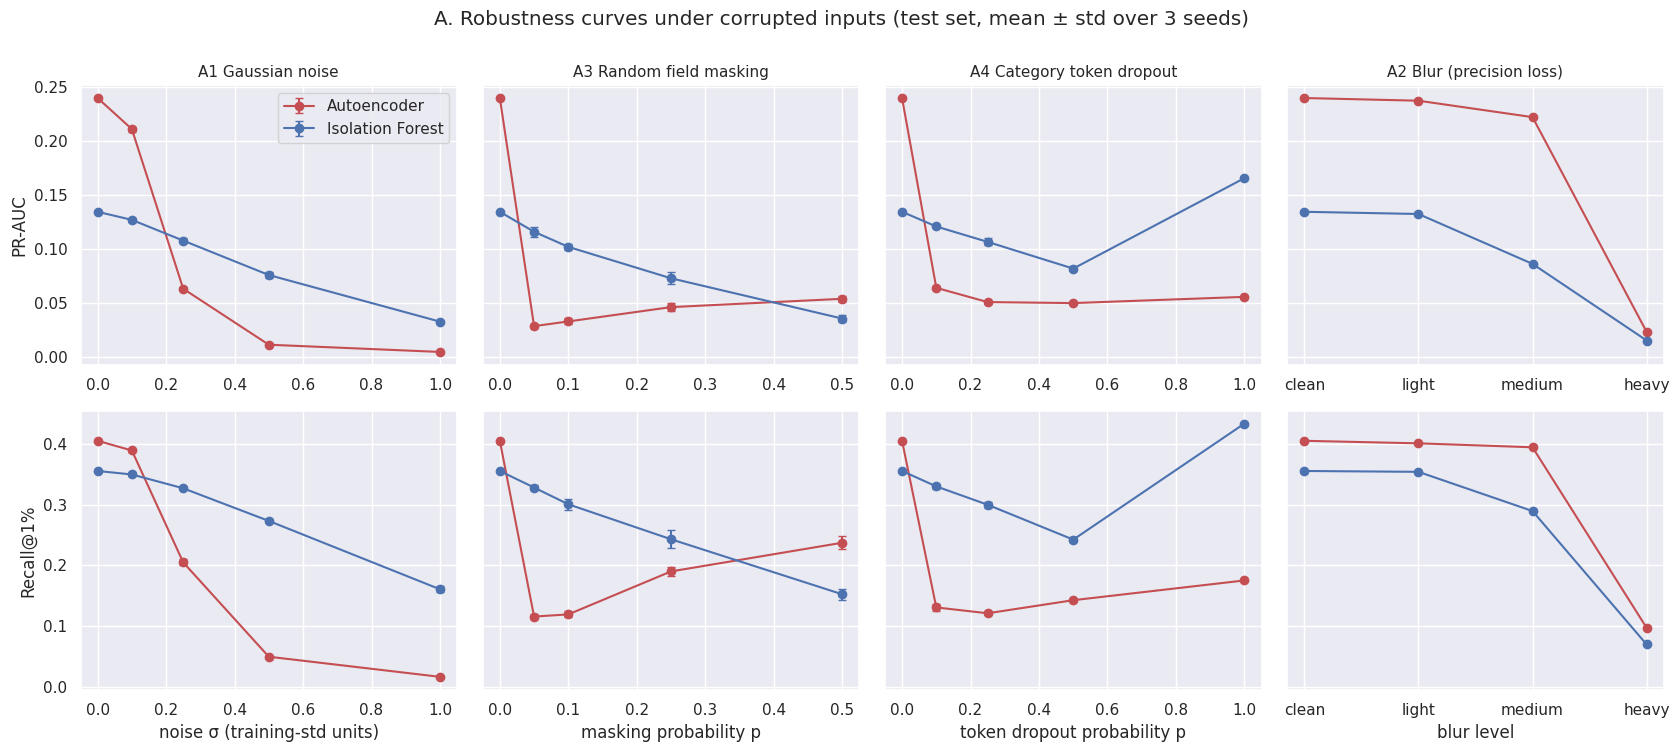

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5), sharey="row")
curves = [("A1 Gaussian noise", "noise σ (training-std units)"), ("A3 Random field masking", "masking probability p"),
          ("A4 Category token dropout", "token dropout probability p"), ("A2 Blur (precision loss)", "blur level")]
colors = {"Autoencoder": "#c44e52", "Isolation Forest": "#4c72b0"}
raw_A = pd.DataFrame([r for r in ROWS if r["family"] == "A. Corrupted inputs"])
for j, (test, xl) in enumerate(curves):
    for i, met in enumerate(["PR-AUC", "Recall@1%"]):
        ax = axes[i, j]
        for m in MODELS:
            sub = raw_A[(raw_A.test == test) & (raw_A.model == m)].groupby("severity")[met].agg(["mean", "std"]).reset_index()
            xs = np.r_[0, sub["severity"]]
            ys = np.r_[CLEAN.loc[m, met], sub["mean"]]
            es = np.r_[0, sub["std"].fillna(0)]
            ax.errorbar(xs, ys, yerr=es, marker="o", capsize=3, label=m, color=colors[m])
        if test.startswith("A2"):
            ax.set_xticks([0, 1, 2, 3]); ax.set_xticklabels(["clean", "light", "medium", "heavy"])
        ax.set_title(test if i == 0 else "", fontsize=11)
        ax.set_xlabel(xl if i == 1 else "")
        if j == 0:
            ax.set_ylabel(met)
axes[0, 0].legend()
plt.suptitle("A. Robustness curves under corrupted inputs (test set, mean ± std over 3 seeds)", y=1.0)
plt.tight_layout()
plt.savefig("outputs/figures/stress_A_corruption_curves.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. B. Partial feature loss
A whole feature group is unavailable for **every** transaction (upstream outage). Two ways the system can respond:
1. **Impute** the missing group with its training mean and keep the deployed model (no retraining).
2. **Fallback model**: an autoencoder retrained (same configuration and seed) on the remaining features only.

In [11]:
FEATURE_GROUPS = {
    "card history (history service down)": ["log_hours_since_last", "amt_vs_card_mean"],
    "amount (amt, amt_vs_card_mean)": ["log_amt", "amt_vs_card_mean"],
    "geolocation (distance_km)": ["distance_km"],
    "time (hour, day, month, weekend, night)": ["hour", "day_of_week", "month", "is_weekend", "is_night"],
    "customer profile (age, gender, city_pop)": ["age", "gender_male", "log_city_pop"],
    "merchant category (one-hot)": CAT_COLS,
}
fallback_rows = []
for gname, cols in FEATURE_GROUPS.items():
    idx = [FI[c] for c in cols]
    Xm = X_te.copy()
    Xm[:, idx] = TRAIN_MEAN[idx]
    for m in MODELS:
        log("B. Partial feature loss", gname, "imputed (deployed model)", m, y_te, score(m, Xm))
    keep = [i for i in range(len(FEATURES)) if i not in idx]
    fb, info = train_ae(X_tr[:, keep], X_va[:, keep], y_va, BEST_CFG, MAX_EPOCHS_FINAL)
    s_fb = recon_error(fb, X_te[:, keep])
    thr_fb = np.quantile(recon_error(fb, X_va[:, keep]), 1 - FLAG_RATE)
    r = log("B. Partial feature loss", gname, "fallback AE retrained without group", "Autoencoder", y_te, s_fb)
    # fixed-threshold metrics must use the fallback model's own validation threshold
    r["Alert rate (fixed thr)"] = float((s_fb >= thr_fb).mean())
    r["Recall (fixed thr)"] = recall_score(y_te, s_fb >= thr_fb)
    print(f"{gname}: fallback trained in {info['train_time_s']:.0f} s")

res_B = summarize(pd.DataFrame([r for r in ROWS if r["family"] == "B. Partial feature loss"]))
res_B[["test", "level", "model", "PR-AUC", "ROC-AUC", "Recall@1%", "Precision@1%", "Alert rate (fixed thr)"]].round(4)

card history (history service down): fallback trained in 5 s
amount (amt, amt_vs_card_mean): fallback trained in 6 s
geolocation (distance_km): fallback trained in 23 s
time (hour, day, month, weekend, night): fallback trained in 9 s
customer profile (age, gender, city_pop): fallback trained in 9 s
merchant category (one-hot): fallback trained in 15 s


,test,level,model,PR-AUC,ROC-AUC,Recall@1%,Precision@1%,Alert rate (fixed thr)
0,card history (history service down),imputed (deployed model),Autoencoder,0.1252,0.8247,0.4751,0.1833,0.3618
1,card history (history service down),imputed (deployed model),Isolation Forest,0.0523,0.8652,0.2009,0.0775,0.0028
2,card history (history service down),fallback AE retrained without group,Autoencoder,0.2190,0.7981,0.3441,0.1328,0.0100
3,"amount (amt, amt_vs_card_mean)",imputed (deployed model),Autoencoder,0.0386,0.6163,0.1506,0.0581,0.0026
4,"amount (amt, amt_vs_card_mean)",imputed (deployed model),Isolation Forest,0.0134,0.7812,0.0583,0.0225,0.0017
5,"amount (amt, amt_vs_card_mean)",fallback AE retrained without group,Autoencoder,0.0534,0.6933,0.1953,0.0754,0.0091
6,geolocation (distance_km),imputed (deployed model),Autoencoder,0.2467,0.6808,0.4065,0.1569,0.0084
7,geolocation (distance_km),imputed (deployed model),Isolation Forest,0.1310,0.8980,0.3678,0.1420,0.0093
8,geolocation (distance_km),fallback AE retrained without group,Autoencoder,0.1536,0.7785,0.5520,0.2130,0.0086
9,"time (hour, day, month, weekend, night)",imputed (deployed model),Autoencoder,0.1601,0.6990,0.3375,0.1303,0.0065


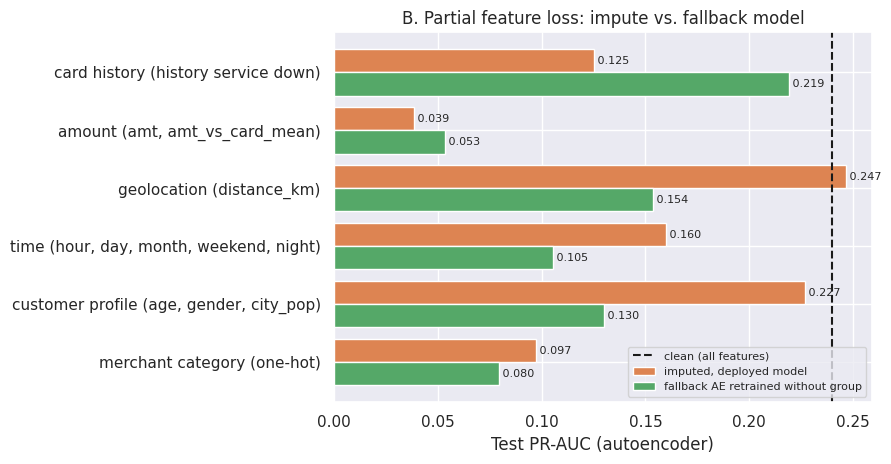

In [12]:
bAE = res_B[res_B.model == "Autoencoder"]
groups = list(FEATURE_GROUPS)
imp = bAE[bAE.level.str.startswith("imputed")].set_index("test").loc[groups, "PR-AUC"]
fbk = bAE[bAE.level.str.startswith("fallback")].set_index("test").loc[groups, "PR-AUC"]
fig, ax = plt.subplots(figsize=(9, 4.8))
yy = np.arange(len(groups))
ax.barh(yy - 0.2, imp, 0.4, label="imputed, deployed model", color="#dd8452")
ax.barh(yy + 0.2, fbk, 0.4, label="fallback AE retrained without group", color="#55a868")
ax.axvline(CLEAN.loc["Autoencoder", "PR-AUC"], color="k", ls="--", label="clean (all features)")
for k in range(len(groups)):
    ax.text(imp.iloc[k], k - 0.2, f" {imp.iloc[k]:.3f}", va="center", fontsize=8)
    ax.text(fbk.iloc[k], k + 0.2, f" {fbk.iloc[k]:.3f}", va="center", fontsize=8)
ax.set_yticks(yy); ax.set_yticklabels(groups); ax.invert_yaxis()
ax.set_xlabel("Test PR-AUC (autoencoder)"); ax.set_title("B. Partial feature loss: impute vs. fallback model")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig("outputs/figures/stress_B_feature_loss.png", dpi=300, bbox_inches="tight")
plt.show()

## 7. C. Out-of-distribution samples
**C1 Natural temporal drift.** The model is trained on Jan 2019 – Mar 2020; the test set (Jun – Dec 2020) is already
out-of-time. We score it month by month: validation period vs. each test month.

In [13]:
months = test_clean["trans_date_trans_time"].dt.to_period("M").astype(str).to_numpy()
for m in MODELS:
    log("C. OOD samples", "C1 temporal drift", "validation (Mar-Jun 2020)", m, y_va, score(m, X_va))
    for mo in sorted(set(months)):
        sel = months == mo
        log("C. OOD samples", "C1 temporal drift", mo, m, y_te[sel], CLEAN_SCORES[m][sel],
            fraud_rate=y_te[sel].mean(), n=int(sel.sum()))
res_C1 = pd.DataFrame([r for r in ROWS if r["test"] == "C1 temporal drift"])
res_C1[["level", "model", "n", "fraud_rate"] + METRIC_COLS].round(4)

,level,model,n,fraud_rate,PR-AUC,ROC-AUC,Precision@1%,Recall@1%,F1@1%,Alert rate (fixed thr),Recall (fixed thr)
0,validation (Mar-Jun 2020),Autoencoder,NaN,NaN,0.3298,0.6943,0.2506,0.4226,0.3146,0.0100,0.4226
1,2020-06,Autoencoder,30058.0,0.0044,0.1985,0.6794,0.1495,0.3383,0.2074,0.0078,0.2857
2,2020-07,Autoencoder,85848.0,0.0037,0.2439,0.6757,0.1478,0.3956,0.2153,0.0095,0.3925
3,2020-08,Autoencoder,88759.0,0.0047,0.1794,0.6555,0.1700,0.3639,0.2318,0.0088,0.3494
4,2020-09,Autoencoder,69533.0,0.0049,0.3662,0.7408,0.2284,0.4676,0.3069,0.0087,0.4559
5,2020-10,Autoencoder,69348.0,0.0055,0.2601,0.6670,0.2089,0.3776,0.2690,0.0093,0.3724
6,2020-11,Autoencoder,72635.0,0.0040,0.2482,0.6866,0.1747,0.4320,0.2488,0.0081,0.4116
7,2020-12,Autoencoder,139538.0,0.0018,0.1900,0.6649,0.0831,0.4496,0.1403,0.0082,0.4341
8,validation (Mar-Jun 2020),Isolation Forest,NaN,NaN,0.2180,0.9102,0.2194,0.3700,0.2754,0.0100,0.3700
9,2020-06,Isolation Forest,30058.0,0.0044,0.1832,0.9126,0.1827,0.4135,0.2535,0.0097,0.4135


**C2 Synthetic covariate shift of the population (benign OOD).** Labels are unchanged; only legitimate behaviour shifts:
price inflation (all amounts × k), customers transacting farther from home (merchant location moved 1–2° north), and an
older customer base (+15 years). Applied to the raw data and pushed through the full pipeline.

In [14]:
def shift_amount(df, k):
    d = df.copy(); d["amt"] = d["amt"] * k; return d
def shift_geo(df, deg):
    d = df.copy(); d["merch_lat"] = d["merch_lat"] + deg; return d
def shift_age(df, years):
    d = df.copy(); d["dob"] = d["dob"] - pd.DateOffset(years=years); return d

SHIFTS = [("C2 amount inflation", f"×{k}", shift_amount, k, k) for k in (1.25, 1.5, 2.0)] + \
         [("C2 merchant farther away", f"+{d}° lat", shift_geo, d, d) for d in (1.0, 2.0)] + \
         [("C2 older customers", "+15 years", shift_age, 15, 15)]
for test, lvl, fn, arg, sev in SHIFTS:
    Xs, _ = prepare_test(fn(test_clean, arg))
    for m in MODELS:
        log("C. OOD samples", test, lvl, m, y_te, score(m, Xs), severity=sev)
    print(test, lvl, "done")
res_C2 = summarize(pd.DataFrame([r for r in ROWS if r["test"].startswith("C2")]))
res_C2[["test", "level", "model"] + METRIC_COLS].round(4)

C2 amount inflation ×1.25 done
C2 amount inflation ×1.5 done
C2 amount inflation ×2.0 done
C2 merchant farther away +1.0° lat done
C2 merchant farther away +2.0° lat done
C2 older customers +15 years done


,test,level,model,PR-AUC,ROC-AUC,Precision@1%,Recall@1%,F1@1%,Alert rate (fixed thr),Recall (fixed thr)
0,C2 amount inflation,×1.25,Autoencoder,0.2450,0.6809,0.1626,0.4214,0.2347,0.0100,0.4214
1,C2 amount inflation,×1.25,Isolation Forest,0.1652,0.9012,0.1520,0.3939,0.2194,0.0142,0.4443
2,C2 amount inflation,×1.5,Autoencoder,0.2472,0.6803,0.1650,0.4275,0.2381,0.0115,0.4392
3,C2 amount inflation,×1.5,Isolation Forest,0.1699,0.9013,0.1598,0.4140,0.2306,0.0155,0.4723
4,C2 amount inflation,×2.0,Autoencoder,0.2466,0.6788,0.1682,0.4359,0.2428,0.0152,0.4578
5,C2 amount inflation,×2.0,Isolation Forest,0.1564,0.8975,0.1596,0.4135,0.2303,0.0198,0.5063
6,C2 merchant farther away,+1.0° lat,Autoencoder,0.0068,0.6371,0.0065,0.0168,0.0093,0.2026,0.5254
7,C2 merchant farther away,+1.0° lat,Isolation Forest,0.1329,0.8881,0.1337,0.3464,0.1929,0.0226,0.4662
8,C2 merchant farther away,+2.0° lat,Autoencoder,0.0039,0.5184,0.0054,0.0140,0.0078,0.6975,0.8154
9,C2 merchant farther away,+2.0° lat,Isolation Forest,0.1502,0.8958,0.1465,0.3795,0.2113,0.0324,0.5319


**C3 Injected out-of-range records.** 1% of legitimate test transactions are replaced by an OOD version
(they stay labelled legitimate). We measure (i) how many OOD records the model flags (**OOD flag rate**) and
(ii) how much fraud recall is lost because OOD records consume the alert budget.
* amount × 100 (beyond the training max), merchant on another continent (~6,000 km), customer age ≈ 120,
  and a corrupted feature vector (every numeric feature at ±5–10 σ: sensor/ETL garbage).

In [15]:
def inject(kind, rng, frac=0.01):
    legit = np.where(y_te == 0)[0]
    idx = np.sort(rng.choice(legit, size=int(frac * len(y_te)), replace=False))
    if kind == "garbage":
        X = X_te.copy()
        X[np.ix_(idx, CONT_IDX)] = (rng.uniform(5, 10, (len(idx), len(CONT_IDX))) *
                                    rng.choice([-1, 1], (len(idx), len(CONT_IDX)))).astype(np.float32)
        return X, idx
    d = test_clean.copy()
    if kind == "amount x100":
        d.loc[idx, "amt"] = d.loc[idx, "amt"] * 100
    elif kind == "merchant abroad":
        d.loc[idx, "merch_lat"], d.loc[idx, "merch_long"] = 48.85, 2.35          # Paris
    elif kind == "age 120":
        d.loc[idx, "dob"] = d.loc[idx, "trans_date_trans_time"] - pd.DateOffset(years=120)
    X, _ = prepare_test(d)
    return X, idx

ood_rows = []
for kind in ["amount x100", "merchant abroad", "age 120", "garbage"]:
    Xo, idx = inject(kind, np.random.default_rng(SEED))
    is_ood = np.zeros(len(y_te), bool); is_ood[idx] = True
    for m in MODELS:
        s = score(m, Xo)
        thr_b = np.quantile(s, 1 - FLAG_RATE)
        r = log("C. OOD samples", "C3 injected OOD (1% of rows)", kind, m, y_te, s,
                **{"OOD flagged @1% budget": float((s[is_ood] >= thr_b).mean()),
                   "OOD flagged (fixed thr)": float((s[is_ood] >= THR[m]).mean()),
                   "share of alerts that are OOD": float(is_ood[s >= thr_b].mean()),
                   "median score OOD / clean legit": float(np.median(s[is_ood]) / np.median(CLEAN_SCORES[m][y_te == 0]))})
    print(kind, "done")
res_C3 = pd.DataFrame([r for r in ROWS if r["test"].startswith("C3")])
res_C3[["level", "model", "PR-AUC", "Recall@1%", "OOD flagged @1% budget", "OOD flagged (fixed thr)",
        "share of alerts that are OOD", "median score OOD / clean legit"]].round(4)

amount x100 done
merchant abroad done
age 120 done
garbage done


,level,model,PR-AUC,Recall@1%,OOD flagged @1% budget,OOD flagged (fixed thr),share of alerts that are OOD,median score OOD / clean legit
0,amount x100,Autoencoder,0.1071,0.3576,0.2132,0.2345,0.2132,1.2104
1,amount x100,Isolation Forest,0.0888,0.3072,0.2275,0.3129,0.2274,1.1186
2,merchant abroad,Autoencoder,0.0343,0.0005,1.0000,1.0000,0.9998,38688.8750
3,merchant abroad,Isolation Forest,0.1330,0.3543,0.0234,0.0319,0.0234,1.0364
4,age 120,Autoencoder,0.2359,0.4042,0.0275,0.0259,0.0275,1.0214
5,age 120,Isolation Forest,0.1285,0.3506,0.0561,0.0763,0.0561,1.0652
6,garbage,Autoencoder,0.0343,0.0005,1.0000,1.0000,0.9998,151.3870
7,garbage,Isolation Forest,0.0384,0.0783,0.9208,0.9996,0.9207,1.2746


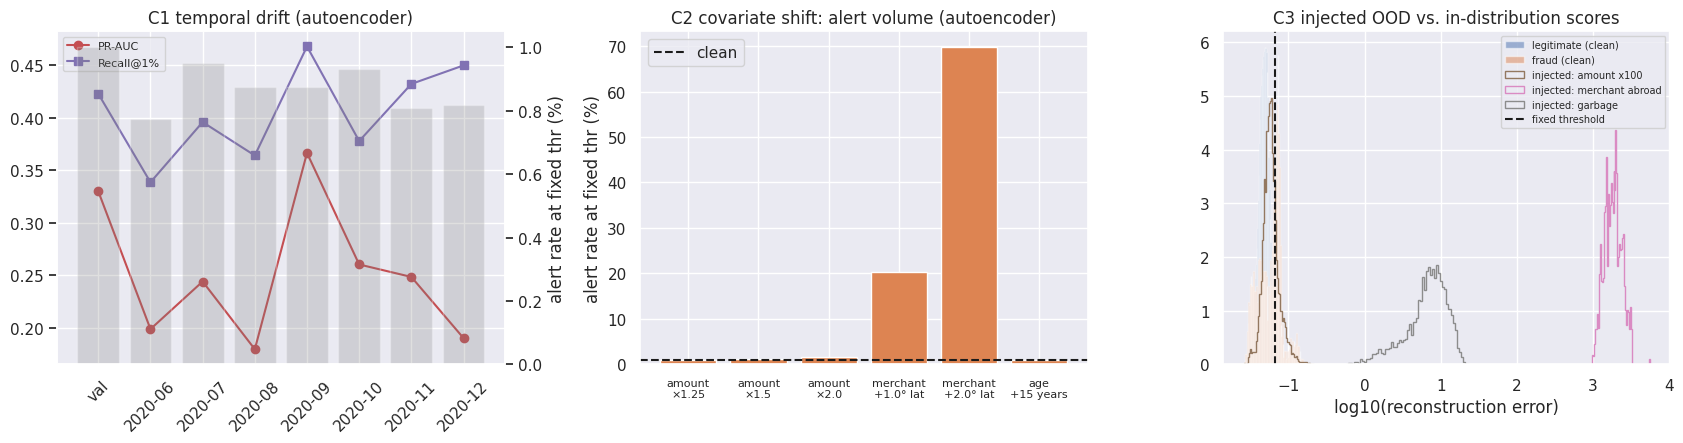

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
# (a) monthly drift
c1 = res_C1[res_C1.model == "Autoencoder"]
ax = axes[0]
ax.plot(c1["level"], c1["PR-AUC"], marker="o", color="#c44e52", label="PR-AUC")
ax.plot(c1["level"], c1["Recall@1%"], marker="s", color="#8172b3", label="Recall@1%")
ax.set_xticks(range(len(c1))); ax.set_xticklabels([l.replace("validation (Mar-Jun 2020)", "val") for l in c1["level"]], rotation=45)
ax2 = ax.twinx(); ax2.bar(range(len(c1)), c1["Alert rate (fixed thr)"] * 100, alpha=0.25, color="gray"); ax2.set_ylabel("alert rate at fixed thr (%)")
ax2.grid(False)
ax.set_title("C1 temporal drift (autoencoder)"); ax.legend(loc="upper left", fontsize=8)
# (b) covariate shift: fixed-threshold alert rate
ax = axes[1]
c2 = res_C2[res_C2.model == "Autoencoder"]
short = {"C2 amount inflation": "amount", "C2 merchant farther away": "merchant", "C2 older customers": "age"}
lab = [f"{short[t]}\n{l}" for t, l in zip(c2["test"], c2["level"])]
ax.bar(range(len(c2)), c2["Alert rate (fixed thr)"] * 100, color="#dd8452")
ax.axhline(CLEAN.loc["Autoencoder", "Alert rate (fixed thr)"] * 100, color="k", ls="--", label="clean")
ax.set_xticks(range(len(c2))); ax.set_xticklabels(lab, fontsize=8)
ax.set_ylabel("alert rate at fixed thr (%)"); ax.set_title("C2 covariate shift: alert volume (autoencoder)"); ax.legend()
# (c) score distribution of injected OOD
ax = axes[2]
s_cl = CLEAN_SCORES["Autoencoder"]
ax.hist(np.log10(s_cl[y_te == 0] + 1e-9), bins=80, density=True, alpha=0.5, label="legitimate (clean)")
ax.hist(np.log10(s_cl[y_te == 1] + 1e-9), bins=80, density=True, alpha=0.5, label="fraud (clean)")
for kind, col in [("amount x100", "#937860"), ("merchant abroad", "#da8bc3"), ("garbage", "#8c8c8c")]:
    Xo, idx = inject(kind, np.random.default_rng(SEED))
    ax.hist(np.log10(recon_error(ae, Xo[idx]) + 1e-9), bins=60, density=True, histtype="step", lw=1.8, label=f"injected: {kind}", color=col)
ax.axvline(np.log10(THR["Autoencoder"]), color="k", ls="--", label="fixed threshold")
ax.set_xlabel("log10(reconstruction error)"); ax.set_title("C3 injected OOD vs. in-distribution scores"); ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig("outputs/figures/stress_C_ood.png", dpi=300, bbox_inches="tight")
plt.show()

## 8. D. Class rarity scenarios
**D1 Test prevalence sweep.** The test set is resampled to different fraud rates (fraud rows subsampled to make
fraud rarer; legitimate rows subsampled to make it more common). 20 resamples per level → mean and 95% interval.
Scores are fixed (the model is not retrained), so any change is due to prevalence alone.

In [17]:
PREVALENCES = [0.02, 0.01, None, 0.001, 0.0005, 0.0002]       # None = native test rate (0.386%)
N_RESAMPLES = 20
fr_idx, lg_idx = np.where(y_te == 1)[0], np.where(y_te == 0)[0]
d1_rows = []
for prev in PREVALENCES:
    for b in range(N_RESAMPLES):
        rng = np.random.default_rng(1000 + b)
        if prev is None:
            sel = rng.choice(len(y_te), len(y_te), replace=True)          # bootstrap of the native set
        elif prev < y_te.mean():
            n_f = max(1, int(round(prev * len(lg_idx) / (1 - prev))))
            sel = np.r_[lg_idx, rng.choice(fr_idx, n_f, replace=False)]
        else:
            n_l = int(round(len(fr_idx) * (1 - prev) / prev))
            sel = np.r_[rng.choice(lg_idx, n_l, replace=False), fr_idx]
        for m in MODELS:
            r = stress_metrics(y_te[sel], CLEAN_SCORES[m][sel], m)
            d1_rows.append({"prevalence": y_te[sel].mean(), "target": "native" if prev is None else prev,
                            "model": m, "n_fraud": int(y_te[sel].sum()), **r})
d1 = pd.DataFrame(d1_rows)
q = lambda p: (lambda x: np.quantile(x, p))
res_D1 = d1.groupby(["target", "model"], sort=False).agg(
    prevalence=("prevalence", "mean"), n_fraud=("n_fraud", "mean"),
    PR_AUC=("PR-AUC", "mean"), PR_AUC_lo=("PR-AUC", q(0.025)), PR_AUC_hi=("PR-AUC", q(0.975)),
    ROC_AUC=("ROC-AUC", "mean"), Precision_1=("Precision@1%", "mean"), Recall_1=("Recall@1%", "mean"),
    Recall_1_lo=("Recall@1%", q(0.025)), Recall_1_hi=("Recall@1%", q(0.975))).reset_index()
for _, r in res_D1.iterrows():
    ROWS.append({"family": "D. Class rarity", "test": "D1 test prevalence sweep", "level": f"fraud rate {r.prevalence:.3%}",
                 "model": r.model, "PR-AUC": r.PR_AUC, "ROC-AUC": r.ROC_AUC, "Precision@1%": r.Precision_1,
                 "Recall@1%": r.Recall_1, "PR-AUC 95% CI": f"[{r.PR_AUC_lo:.4f}, {r.PR_AUC_hi:.4f}]"})
res_D1.round(4)

,target,model,prevalence,n_fraud,PR_AUC,PR_AUC_lo,PR_AUC_hi,ROC_AUC,Precision_1,Recall_1,Recall_1_lo,Recall_1_hi
0,0.02,Autoencoder,0.0200,2145.0,0.3929,0.3886,0.3983,0.6813,0.6781,0.3392,0.3371,0.3432
1,0.02,Isolation Forest,0.0200,2145.0,0.3525,0.3424,0.3618,0.8967,0.5687,0.2845,0.2787,0.2884
2,0.01,Autoencoder,0.0100,2145.0,0.3282,0.3240,0.3324,0.6813,0.3837,0.3838,0.3825,0.3855
3,0.01,Isolation Forest,0.0100,2145.0,0.2474,0.2403,0.2523,0.8967,0.3297,0.3297,0.3277,0.3336
4,native,Autoencoder,0.0039,2152.2,0.2403,0.2280,0.2585,0.6826,0.1571,0.4058,0.3886,0.4343
5,native,Isolation Forest,0.0039,2152.2,0.1371,0.1267,0.1535,0.8960,0.1372,0.3544,0.3394,0.3718
6,0.001,Autoencoder,0.0010,554.0,0.1379,0.1204,0.1521,0.6789,0.0409,0.4088,0.3693,0.4429
7,0.001,Isolation Forest,0.0010,554.0,0.0467,0.0372,0.0568,0.8961,0.0367,0.3673,0.3402,0.4037
8,0.0005,Autoencoder,0.0005,277.0,0.1053,0.0682,0.1411,0.6669,0.0203,0.4063,0.3567,0.4495
9,0.0005,Isolation Forest,0.0005,277.0,0.0251,0.0173,0.0340,0.8941,0.0178,0.3558,0.3230,0.4047


**D2 Rare fraud sub-types.** Fraud recall at the 1% budget broken down by merchant category and by amount band,
next to how many fraud examples of that kind exist in the training split. Small, low-amount fraud patterns are rare
*and* look normal, which is where an unsupervised detector is expected to fail.

In [18]:
cat_te = te_feat["category"].to_numpy()
amt_te = test_clean["amt"].to_numpy()
cat_tr_fraud = tr_feat.loc[tr_feat.is_fraud == 1, "category"].value_counts()
d2_rows = []
for m in MODELS:
    s = CLEAN_SCORES[m]
    flag = s >= np.quantile(s, 1 - FLAG_RATE)
    for c in CATEGORIES:
        sel = (cat_te == c) & (y_te == 1)
        d2_rows.append({"model": m, "group": "category", "value": c, "train fraud": int(cat_tr_fraud.get(c, 0)),
                        "test fraud": int(sel.sum()), "Recall@1%": flag[sel].mean()})
    bands = [(0, 50), (50, 200), (200, 500), (500, 1000), (1000, np.inf)]
    amt_tr = train_clean["amt"].iloc[:split_idx].to_numpy()
    for lo, hi in bands:
        sel = (amt_te >= lo) & (amt_te < hi) & (y_te == 1)
        n_tr = int(((amt_tr >= lo) & (amt_tr < hi) & (y_tr == 1)).sum())
        d2_rows.append({"model": m, "group": "amount band", "value": f"${lo:g}–{hi:g}".replace("inf", "∞"),
                        "train fraud": n_tr, "test fraud": int(sel.sum()), "Recall@1%": flag[sel].mean()})
res_D2 = pd.DataFrame(d2_rows)
res_D2_w = res_D2.pivot_table(index=["group", "value", "train fraud", "test fraud"], columns="model",
                              values="Recall@1%", sort=False).reset_index()
res_D2_w.round(3)

model,group,value,train fraud,test fraud,Autoencoder,Isolation Forest
0,category,entertainment,184,59,0.119,0.169
1,category,food_dining,119,54,0.093,0.000
2,category,gas_transport,493,154,0.084,0.006
3,category,grocery_net,110,41,0.098,0.024
4,category,grocery_pos,1387,485,0.039,0.076
5,category,health_fitness,103,52,0.000,0.000
6,category,home,151,67,0.000,0.045
7,category,kids_pets,191,65,0.015,0.000
8,category,misc_net,737,267,0.727,0.794
9,category,misc_pos,193,72,0.264,0.125


**D3 Fraud contamination of the training data.** The autoencoder is unsupervised and trained on *all* transactions,
so fraud hidden in training is learned as "normal". We retrain (same configuration and seed) with the training fraud
rate set to 0% (legitimate only), native (0.575%), 2% and 5% (fraud rows over-sampled), and evaluate on the clean test set.

In [19]:
tr_f, tr_l = np.where(y_tr == 1)[0], np.where(y_tr == 0)[0]
for name, rate in [("0% (legitimate only)", 0.0), ("native 0.575%", None), ("2%", 0.02), ("5%", 0.05)]:
    if rate is None:
        model_d3, s_va3 = ae, score("Autoencoder", X_va)
    else:
        rng = np.random.default_rng(SEED)
        n_f = int(round(rate * len(tr_l) / (1 - rate)))
        sel = np.r_[tr_l, rng.choice(tr_f, n_f, replace=True)] if n_f else tr_l
        model_d3, _ = train_ae(X_tr[np.sort(sel)], X_va, y_va, BEST_CFG, MAX_EPOCHS_FINAL)
        s_va3 = recon_error(model_d3, X_va)
    s3 = recon_error(model_d3, X_te)
    thr3 = np.quantile(s_va3, 1 - FLAG_RATE)
    r = log("D. Class rarity", "D3 training fraud contamination", name, "Autoencoder", y_te, s3)
    r["Alert rate (fixed thr)"] = float((s3 >= thr3).mean()); r["Recall (fixed thr)"] = recall_score(y_te, s3 >= thr3)
    print(name, "done")
res_D3 = pd.DataFrame([r for r in ROWS if r["test"].startswith("D3")])
res_D3[["level"] + METRIC_COLS].round(4)

0% (legitimate only) done
native 0.575% done
2% done
5% done


,level,PR-AUC,ROC-AUC,Precision@1%,Recall@1%,F1@1%,Alert rate (fixed thr),Recall (fixed thr)
0,0% (legitimate only),0.2449,0.6908,0.1632,0.4228,0.2355,0.0091,0.4200
1,native 0.575%,0.2400,0.6813,0.1567,0.4061,0.2261,0.0087,0.3916
2,2%,0.0610,0.6091,0.0621,0.1608,0.0896,0.0095,0.1576
3,5%,0.0766,0.7491,0.0434,0.1124,0.0626,0.0106,0.1170


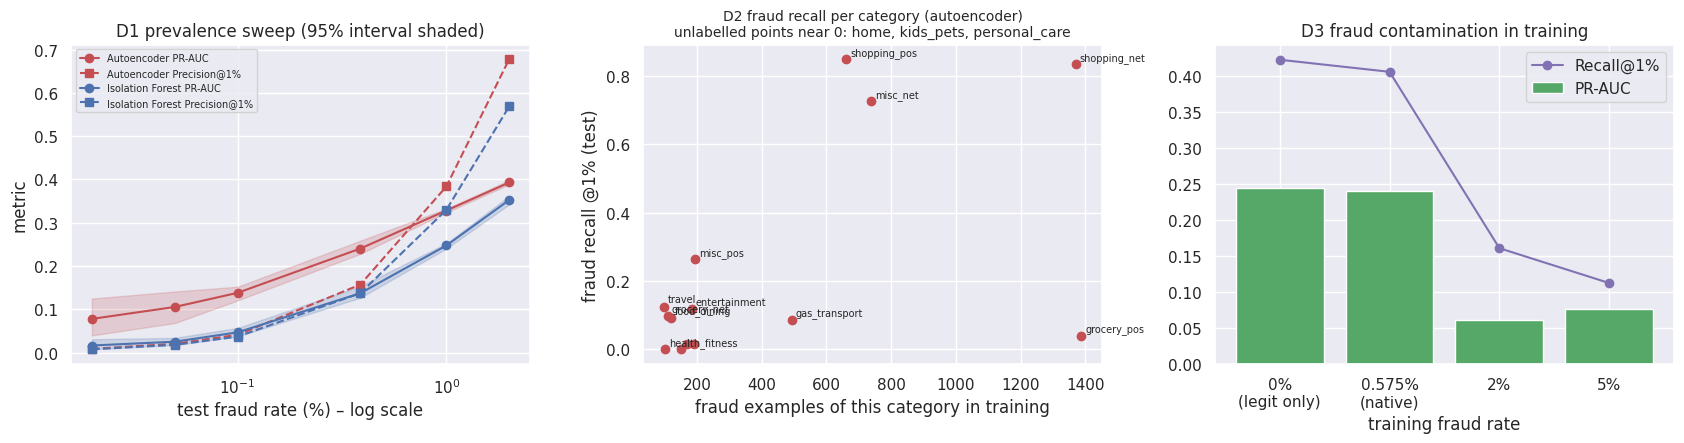

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
ax = axes[0]
for m in MODELS:
    sub = res_D1[res_D1.model == m].sort_values("prevalence")
    ax.plot(sub.prevalence * 100, sub.PR_AUC, marker="o", color=colors[m], label=f"{m} PR-AUC")
    ax.fill_between(sub.prevalence * 100, sub.PR_AUC_lo, sub.PR_AUC_hi, color=colors[m], alpha=0.2)
    ax.plot(sub.prevalence * 100, sub.Precision_1, marker="s", ls="--", color=colors[m], label=f"{m} Precision@1%")
ax.set_xscale("log"); ax.set_xlabel("test fraud rate (%) – log scale"); ax.set_ylabel("metric")
ax.set_title("D1 prevalence sweep (95% interval shaded)"); ax.legend(fontsize=7)
ax = axes[1]
cat = res_D2[(res_D2.group == "category") & (res_D2.model == "Autoencoder")].sort_values("train fraud")
ax.scatter(cat["train fraud"], cat["Recall@1%"], color="#c44e52")
for _, r in cat.iterrows():
    if r["Recall@1%"] > 0.05 or r["value"] in ("grocery_pos", "health_fitness"):
        ax.annotate(r["value"], (r["train fraud"], r["Recall@1%"]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("fraud examples of this category in training"); ax.set_ylabel("fraud recall @1% (test)")
ax.set_title("D2 fraud recall per category (autoencoder)\nunlabelled points near 0: home, kids_pets, personal_care", fontsize=10)
ax = axes[2]
d3_lab = ["0%\n(legit only)", "0.575%\n(native)", "2%", "5%"]
ax.bar(d3_lab, res_D3["PR-AUC"], color="#55a868", label="PR-AUC")
ax.plot(d3_lab, res_D3["Recall@1%"], marker="o", color="#8172b3", label="Recall@1%")
ax.set_title("D3 fraud contamination in training"); ax.set_xlabel("training fraud rate"); ax.legend()
plt.tight_layout()
plt.savefig("outputs/figures/stress_D_rarity.png", dpi=300, bbox_inches="tight")
plt.show()

## 9. Summary table (autoencoder; worst level of each test vs. clean)

In [21]:
all_df = pd.DataFrame(ROWS)
all_sum = all_df.groupby(["family", "test", "level", "model"], sort=False)[METRIC_COLS].mean().reset_index()
clean_ae = CLEAN.loc["Autoencoder"]
ae_sum = all_sum[all_sum.model == "Autoencoder"].copy()
ae_sum["ΔPR-AUC vs clean"] = ae_sum["PR-AUC"] - clean_ae["PR-AUC"]
ae_sum["ΔRecall@1% vs clean"] = ae_sum["Recall@1%"] - clean_ae["Recall@1%"]
ae_sum[["family", "test", "level", "PR-AUC", "ΔPR-AUC vs clean", "Recall@1%", "ΔRecall@1% vs clean",
        "Precision@1%", "Alert rate (fixed thr)"]].round(4)

,family,test,level,PR-AUC,ΔPR-AUC vs clean,Recall@1%,ΔRecall@1% vs clean,Precision@1%,Alert rate (fixed thr)
0,0. Clean,clean test set,none,0.2400,0.0000,0.4061,0.0000,0.1567,0.0087
2,A. Corrupted inputs,A1 Gaussian noise,σ=0.1,0.2112,-0.0288,0.3901,-0.0160,0.1505,0.0122
4,A. Corrupted inputs,A1 Gaussian noise,σ=0.25,0.0634,-0.1766,0.2051,-0.2009,0.0792,0.0575
6,A. Corrupted inputs,A1 Gaussian noise,σ=0.5,0.0116,-0.2284,0.0493,-0.3568,0.0190,0.3127
8,A. Corrupted inputs,A1 Gaussian noise,σ=1.0,0.0049,-0.2351,0.0160,-0.3901,0.0062,0.7456
...,...,...,...,...,...,...,...,...,...
134,D. Class rarity,D1 test prevalence sweep,fraud rate 0.020%,0.0778,-0.1622,0.4216,0.0156,0.0085,NaN
136,D. Class rarity,D3 training fraud contamination,0% (legitimate only),0.2449,0.0049,0.4228,0.0168,0.1632,0.0091
137,D. Class rarity,D3 training fraud contamination,native 0.575%,0.2400,0.0000,0.4061,0.0000,0.1567,0.0087
138,D. Class rarity,D3 training fraud contamination,2%,0.0610,-0.1790,0.1608,-0.2452,0.0621,0.0095


## 10. Save results

In [22]:
all_df.to_csv("outputs/results/stress_tests_all_runs.csv", index=False)
all_sum.to_csv("outputs/results/stress_tests_summary.csv", index=False)
res_D1.to_csv("outputs/results/stress_D1_prevalence.csv", index=False)
res_D2_w.to_csv("outputs/results/stress_D2_rare_subtypes.csv", index=False)
print(sorted(f for f in os.listdir("outputs/results") if f.startswith("stress")))
print(sorted(f for f in os.listdir("outputs/figures") if f.startswith("stress")))

['stress_D1_prevalence.csv', 'stress_D2_rare_subtypes.csv', 'stress_tests_all_runs.csv', 'stress_tests_summary.csv']
['stress_A_corruption_curves.png', 'stress_B_feature_loss.png', 'stress_C_ood.png', 'stress_D_rarity.png']


In [23]:
# ## 11. Efficiency: training and inference (clean vs. corrupted inputs)
# Same reporting style as Milestone 2: single-transaction latency (p50/p90/p95, after warm-up),
# batch throughput on the full test set, model size and training time, on the same CPU runtime.
import joblib

def latency_ms(fn, n_calls, warmup=20):
    for _ in range(warmup):
        fn()
    t = []
    for _ in range(n_calls):
        t0 = time.perf_counter(); fn(); t.append((time.perf_counter() - t0) * 1000)
    return np.percentile(t, 50), np.percentile(t, 90), np.percentile(t, 95)

# training time of the final autoencoder (same configuration and seed -> same model)
_, train_info = train_ae(X_tr, X_va, y_va, BEST_CFG, MAX_EPOCHS_FINAL)
t0 = time.time()
IsolationForest(**IF_CFG, contamination="auto", random_state=SEED, n_jobs=-1).fit(X_tr)
if_fit_s = time.time() - t0

# model size on disk (the Isolation Forest file is only written to measure it, then deleted)
torch.save(ae.state_dict(), "outputs/models/autoencoder.pt")
joblib.dump(iso, "_if_size_check.joblib")
size_kb = {"Autoencoder": os.path.getsize("outputs/models/autoencoder.pt") / 1024,
           "Isolation Forest": os.path.getsize("_if_size_check.joblib") / 1024}
os.remove("_if_size_check.joblib")
n_params = sum(p.numel() for p in ae.parameters())

rng = np.random.default_rng(SEED)
INPUTS = {"clean": X_te,
          "A1 noise σ=0.25": add_noise(X_te, 0.25, rng),
          "A3 masking p=0.10": mask_fields(X_te, 0.10, rng),
          "A4 category dropout p=0.5": drop_category(X_te, 0.50, rng)}

eff_rows = []
for name, X in INPUTS.items():
    for m in MODELS:
        if m == "Isolation Forest":
            iso.set_params(n_jobs=1)            # one request = one thread
        rows_it = iter(range(10**7))
        n_calls = 1000 if m == "Autoencoder" else 200
        p50, p90, p95 = latency_ms(lambda: score(m, X[next(rows_it) % 5000:][:1]), n_calls)
        if m == "Isolation Forest":
            iso.set_params(n_jobs=-1)
        t0 = time.perf_counter(); score(m, X); batch_s = time.perf_counter() - t0
        eff_rows.append({"input": name, "model": m, "latency p50 (ms)": p50, "latency p90 (ms)": p90,
                         "latency p95 (ms)": p95, "throughput (txn/s)": len(X) / batch_s,
                         "full test set (s)": batch_s})
eff_df = pd.DataFrame(eff_rows)

print(f"Hardware: {os.cpu_count()} CPU cores, device = {device}, torch {torch.__version__}")
print(f"Autoencoder: {n_params} parameters, {size_kb['Autoencoder']:.1f} KB on disk, "
      f"training {train_info['train_time_s']:.1f} s ({train_info['epochs_run']} epochs, best {train_info['best_epoch']})")
print(f"Isolation Forest: {size_kb['Isolation Forest']:.0f} KB on disk, training {if_fit_s:.1f} s")
eff_df.round(4)

Hardware: 2 CPU cores, device = cuda, torch 2.14.1+cu130
Autoencoder: 1154 parameters, 8.2 KB on disk, training 5.8 s (6 epochs, best 3)
Isolation Forest: 1304 KB on disk, training 0.8 s


,input,model,latency p50 (ms),latency p90 (ms),latency p95 (ms),throughput (txn/s),full test set (s)
0,clean,Autoencoder,0.3675,0.4266,0.4559,2.315738e+07,0.0240
1,clean,Isolation Forest,6.2248,8.0039,10.8667,2.488546e+05,2.2331
2,A1 noise σ=0.25,Autoencoder,0.3738,0.4438,0.4780,2.331803e+07,0.0238
3,A1 noise σ=0.25,Isolation Forest,6.3354,7.8659,10.4861,1.901013e+05,2.9233
4,A3 masking p=0.10,Autoencoder,0.5831,0.6567,0.6854,2.156723e+07,0.0258
5,A3 masking p=0.10,Isolation Forest,6.2578,6.7607,7.8425,2.474212e+05,2.2460
6,A4 category dropout p=0.5,Autoencoder,0.3661,0.4475,0.5622,2.336853e+07,0.0238
7,A4 category dropout p=0.5,Isolation Forest,6.2629,7.0187,7.5937,2.694060e+05,2.0628


# Section 2 — Robustness & Security (extension to Section 1.3)
Run the Section 1.3 notebook cells above first. This extension reuses the **same** 26 features, StandardScaler, split, AE architecture, validation threshold, corruption function and CPU environment. It adds denoising training, sanitization, constrained white-box FGSM/PGD, calibration, efficiency and case studies. The new results are written to `outputs/results/section2_*` and `outputs/figures/section2_*`. Do not use test labels for training or threshold selection.


In [24]:
# 2.1 Denoising AE: Gaussian perturbation ONLY on the nine standardized continuous features.
# The clean input remains the reconstruction target. Validation uses clean reconstruction loss.
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
import gc

def train_dae(sigma=0.10, seed=42):
    set_seed(seed)
    m = AutoEncoder(X_tr.shape[1], BEST_CFG['hidden'], BEST_CFG['bottleneck']).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=BEST_CFG['lr'], weight_decay=BEST_CFG['weight_decay'])
    Xt = torch.from_numpy(X_tr).to(device); Xv = torch.from_numpy(X_va).to(device)
    best, state, wait = np.inf, None, 0
    start = time.perf_counter()
    for epoch in range(MAX_EPOCHS_FINAL):
        m.train()
        for idx in torch.randperm(len(Xt),device=device).split(BATCH_SIZE):
            clean = Xt[idx]; noisy = clean.clone()
            noisy[:,CONT_IDX] += sigma*torch.randn_like(noisy[:,CONT_IDX])
            loss = ((m(noisy)-clean)**2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
        vl = recon_error(m,Xv).mean()
        if vl < best-MIN_DELTA:
            best, state, wait = vl, {k:v.detach().clone() for k,v in m.state_dict().items()},0
        else:
            wait += 1
            if wait>=PATIENCE: break
    m.load_state_dict(state); m.eval()
    return m, time.perf_counter()-start

DAE_SIGMA=0.10
DAE_SEEDS=[42,43,44]
daes=[]; train_times=[]
for sd in DAE_SEEDS:
    m, seconds=train_dae(DAE_SIGMA,sd)
    daes.append(m); train_times.append(seconds)
print('DAE training seconds:',train_times)

# Sanitization uses training-only feature bounds; binary and one-hot features remain unchanged.
LOW=np.quantile(X_tr[:,CONT_IDX],0.0005,axis=0).astype(np.float32)
HIGH=np.quantile(X_tr[:,CONT_IDX],0.9995,axis=0).astype(np.float32)
def sanitize(X):
    z=np.asarray(X,dtype=np.float32).copy()
    v=z[:,CONT_IDX]; invalid=~np.isfinite(v)
    v=np.where(invalid,0.0,v)
    z[:,CONT_IDX]=np.clip(v,LOW,HIGH)
    # Invalid categorical/binary entries are NOT silently repaired: queue them.
    other=np.array([j for j in range(z.shape[1]) if j not in CONT_IDX])
    bad_other=~np.isfinite(z[:,other]).all(axis=1)
    bad_cat=~np.isclose(z[:,CAT_IDX].sum(axis=1),1.0)
    bad_bin=~np.isin(z[:,[FI['is_weekend'],FI['is_night'],FI['gender_male']]], [0,1]).all(axis=1)
    dq=invalid.any(axis=1)|bad_other|bad_cat|bad_bin
    return z,dq

PIPELINES={'Original AE': [ae], 'DAE seed42':[daes[0]], 'DAE seed43':[daes[1]], 'DAE seed44':[daes[2]], 'DAE ensemble':daes}
def pipeline_scores(name,X):
    z,_=sanitize(X) if name.endswith('+ sanitize') else (X,None)
    base=name.replace(' + sanitize','')
    return np.mean([recon_error(m,z) for m in PIPELINES[base]],axis=0)
PIPELINES['DAE ensemble + sanitize']=daes
PIPELINES['Original AE + sanitize']=[ae]
THRESH2={name:float(np.quantile(pipeline_scores(name,X_va),0.99)) for name in PIPELINES}
print('Validation thresholds:',THRESH2)


DAE training seconds: [6.9066203270003825, 6.451347803000317, 14.515403661000164]
Validation thresholds: {'Original AE': 0.06631690263748169, 'DAE seed42': 0.06677383929491043, 'DAE seed43': 0.08648160099983215, 'DAE seed44': 0.08649734407663345, 'DAE ensemble': 0.07827872782945633, 'DAE ensemble + sanitize': 0.07824940234422684, 'Original AE + sanitize': 0.06627336144447327}


In [25]:
# 2.2 Adaptive white-box attacks on fraud rows only.
# Attack minimizes reconstruction error, subject to L-infinity budget in scaled units.
# Only log_amt and distance_km are mutable; one-hot, history, time and profile remain fixed.
# Attacks are reoptimized against EACH defended pipeline (including sanitization).
# MUTABLE=[FI['log_amt'],FI['distance_km']]

MUTABLE = []

for feat in [
    'log_amt',
    'distance_km',
    'txn_count_1h',
    'txn_count_24h',
    'log_secs_since_last'
]:
    if feat in FI:
        MUTABLE.append(FI[feat])

print("Mutable attack features:",
      [k for k,v in FI.items() if v in MUTABLE])


def attack_fraud(name, X_fraud, epsilon, steps=1, batch_size=2048):

    models = PIPELINES[name]
    defended = name.endswith('+ sanitize')

    out = []

    for start in range(0, len(X_fraud), batch_size):

        original = torch.as_tensor(
            X_fraud[start:start+batch_size],
            dtype=torch.float32,
            device=device
        )

        current = original.clone()

        step = epsilon if steps == 1 else 2.0 * epsilon / steps

        for _ in range(steps):

            current = current.detach().requires_grad_(True)

            xx = current.clone()

            # Adaptive attacker sees sanitization transform
            if defended:
                lo = torch.as_tensor(LOW, device=device)
                hi = torch.as_tensor(HIGH, device=device)

                xx[:, CONT_IDX] = torch.maximum(
                    torch.minimum(xx[:, CONT_IDX], hi),
                    lo
                )

            obj = torch.stack(
                [
                    ((m(xx) - xx) ** 2).mean(dim=1)
                    for m in models
                ]
            ).mean(dim=0).sum()

            grad = torch.autograd.grad(obj, current)[0]

            with torch.no_grad():

                nxt = current.detach().clone()

                nxt[:, MUTABLE] -= (
                    step *
                    grad[:, MUTABLE].sign()
                )

                nxt[:, MUTABLE] = torch.max(
                    torch.min(
                        nxt[:, MUTABLE],
                        original[:, MUTABLE] + epsilon
                    ),
                    original[:, MUTABLE] - epsilon
                )

                # Distance cannot become negative
                if 'distance_km' in FI:

                    dist_floor = float(
                        (
                            0.0
                            -
                            scaler.mean_[
                                SCALE_COLS.index('distance_km')
                            ]
                        )
                        /
                        scaler.scale_[
                            SCALE_COLS.index('distance_km')
                        ]
                    )

                    nxt[:, FI['distance_km']].clamp_(
                        min=dist_floor
                    )

                current = nxt

        out.append(current.detach().cpu().numpy())

    return np.concatenate(out, axis=0)


# ==========================================================
# Robustness experiments
# ==========================================================

EPSILONS = [0.0, 0.1, 0.25, 0.5]

SECTION2_ROWS = []

ATTACK_CACHE = {}


def evaluate(name, scenario, strength, X):

    s = pipeline_scores(name, X)

    thr = THRESH2[name]

    pred = s >= thr

    SECTION2_ROWS.append({

        'pipeline': name,
        'scenario': scenario,
        'strength': strength,

        'PR-AUC':
            average_precision_score(y_te, s),

        'ROC-AUC':
            roc_auc_score(y_te, s),

        'Precision_fixed':
            precision_score(
                y_te,
                pred,
                zero_division=0
            ),

        'Recall_fixed':
            recall_score(
                y_te,
                pred,
                zero_division=0
            ),

        'F1_fixed':
            f1_score(
                y_te,
                pred,
                zero_division=0
            ),

        'Alert_rate_fixed':
            pred.mean(),

        'Recall_at_1pct_budget':
            recall_score(
                y_te,
                s >= np.quantile(s, 0.99),
                zero_division=0
            )

    })

    return s


# ==========================================================
# Clean / noise / FGSM / PGD
# ==========================================================

for name in PIPELINES:

    evaluate(name, 'clean', 0, X_te)

    # Gaussian corruption
    for sigma in [0.05, 0.1, 0.15, 0.2, 0.3]:

        Xn = add_noise(
            X_te,
            sigma,
            np.random.default_rng(42)
        )

        evaluate(
            name,
            'Gaussian noise',
            sigma,
            Xn
        )

    # FGSM + PGD
    for method, steps in [

        ('FGSM', 1),
        ('PGD', 20)

    ]:

        for eps in EPSILONS[1:]:

            attacked = attack_fraud(
                name,
                X_te[y_te == 1],
                eps,
                steps=steps
            )

            Xa = X_te.copy()
            Xa[y_te == 1] = attacked

            s = evaluate(
                name,
                method,
                eps,
                Xa
            )

            if method == 'PGD' and eps == 0.5:
                ATTACK_CACHE[name] = (Xa, s)


# ==========================================================
# Final metrics dataframe
# ==========================================================

section2 = pd.DataFrame(SECTION2_ROWS)

for pipe in section2.pipeline.unique():

    clean_prauc = section2[
        (section2.pipeline == pipe)
        &
        (section2.scenario == 'clean')
    ]['PR-AUC'].iloc[0]

    clean_recall = section2[
        (section2.pipeline == pipe)
        &
        (section2.scenario == 'clean')
    ]['Recall_at_1pct_budget'].iloc[0]

    # Robust-accuracy equivalent
    section2.loc[
        section2.pipeline == pipe,
        'PR_AUC_retention'
    ] = (
        section2.loc[
            section2.pipeline == pipe,
            'PR-AUC'
        ]
        /
        clean_prauc
    )

    # Recall retention
    section2.loc[
        section2.pipeline == pipe,
        'Recall_retention'
    ] = (
        section2.loc[
            section2.pipeline == pipe,
            'Recall_at_1pct_budget'
        ]
        /
        clean_recall
    )


section2.to_csv(
    'outputs/results/section2_metrics.csv',
    index=False
)

display(section2.round(4))


Mutable attack features: ['log_amt', 'distance_km']


,pipeline,scenario,strength,PR-AUC,ROC-AUC,Precision_fixed,Recall_fixed,F1_fixed,Alert_rate_fixed,Recall_at_1pct_budget,PR_AUC_retention,Recall_retention
0,Original AE,clean,0.00,0.2400,0.6813,0.1747,0.3916,0.2416,0.0087,0.4061,1.0000,1.0000
1,Original AE,Gaussian noise,0.05,0.2348,0.6816,0.1632,0.4005,0.2318,0.0095,0.4065,0.9785,1.0011
2,Original AE,Gaussian noise,0.10,0.2128,0.6820,0.1296,0.4117,0.1972,0.0123,0.3925,0.8869,0.9667
3,Original AE,Gaussian noise,0.15,0.1652,0.6822,0.0869,0.4280,0.1444,0.0190,0.3585,0.6885,0.8829
4,Original AE,Gaussian noise,0.20,0.1079,0.6820,0.0518,0.4438,0.0928,0.0331,0.2951,0.4497,0.7268
...,...,...,...,...,...,...,...,...,...,...,...,...
79,Original AE + sanitize,FGSM,0.25,0.2428,0.6775,0.1769,0.3977,0.2449,0.0087,0.4103,0.9745,1.0092
80,Original AE + sanitize,FGSM,0.50,0.3006,0.7095,0.1921,0.4401,0.2675,0.0088,0.4466,1.2068,1.0986
81,Original AE + sanitize,PGD,0.10,0.2374,0.6752,0.1728,0.3865,0.2388,0.0086,0.4000,0.9529,0.9839
82,Original AE + sanitize,PGD,0.25,0.2272,0.6720,0.1712,0.3823,0.2365,0.0086,0.3939,0.9120,0.9690


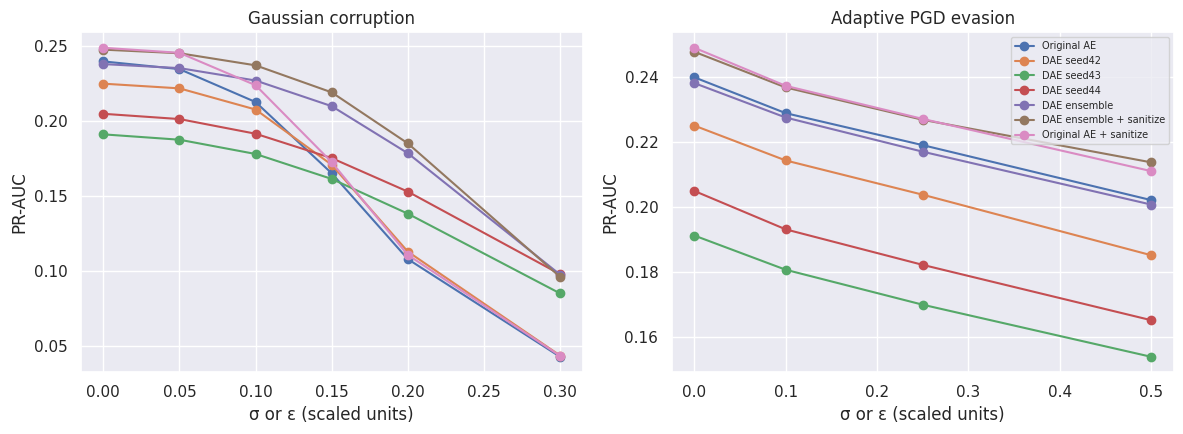

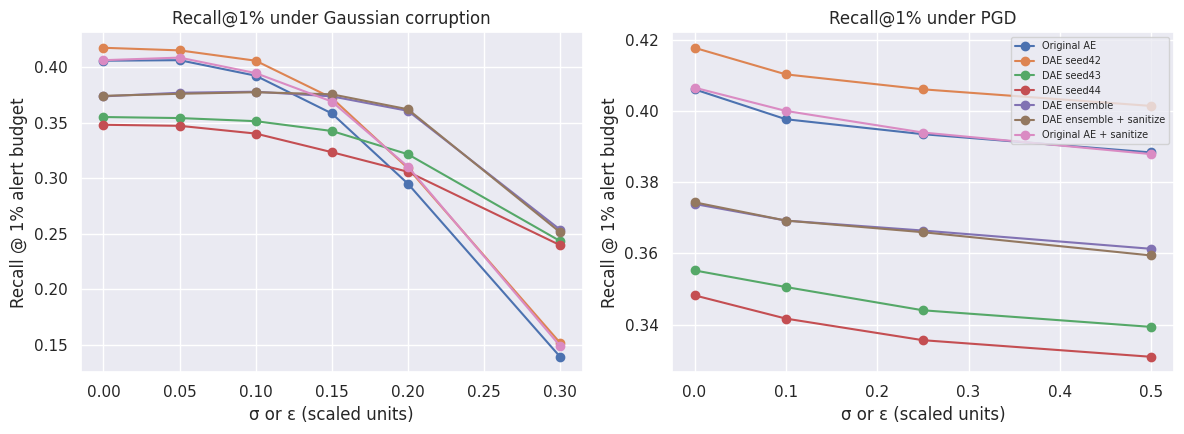

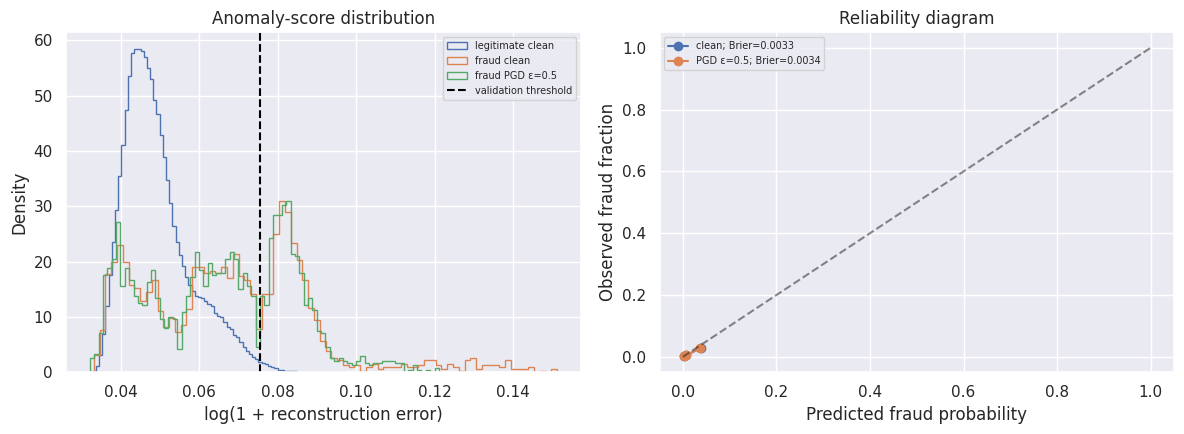

In [26]:
# ==========================================================
# Robustness curves
# ==========================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for name in PIPELINES:

    # Gaussian corruption
    d = section2[
        (section2.pipeline == name)
        &
        (section2.scenario == 'Gaussian noise')
    ].sort_values('strength')

    clean = section2[
        (section2.pipeline == name)
        &
        (section2.scenario == 'clean')
    ]

    axes[0].plot(
        [0] + d.strength.tolist(),
        [clean['PR-AUC'].iloc[0]] + d['PR-AUC'].tolist(),
        marker='o',
        label=name
    )

    # PGD
    d = section2[
        (section2.pipeline == name)
        &
        (section2.scenario == 'PGD')
    ].sort_values('strength')

    axes[1].plot(
        [0] + d.strength.tolist(),
        [clean['PR-AUC'].iloc[0]] + d['PR-AUC'].tolist(),
        marker='o',
        label=name
    )

axes[0].set_title('Gaussian corruption')
axes[1].set_title('Adaptive PGD evasion')

for ax in axes:
    ax.set_xlabel('σ or ε (scaled units)')
    ax.set_ylabel('PR-AUC')
    ax.grid(True)

axes[1].legend(fontsize=7)

fig.tight_layout()

fig.savefig(
    'outputs/figures/section2_robustness_curves.png',
    dpi=180
)

plt.show()


# ==========================================================
# Recall@1% robustness curves
# ==========================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for name in PIPELINES:

    clean = section2[
        (section2.pipeline == name)
        &
        (section2.scenario == 'clean')
    ]

    # Gaussian corruption
    d = section2[
        (section2.pipeline == name)
        &
        (section2.scenario == 'Gaussian noise')
    ].sort_values('strength')

    axes[0].plot(
        [0] + d.strength.tolist(),
        [clean['Recall_at_1pct_budget'].iloc[0]]
        + d['Recall_at_1pct_budget'].tolist(),
        marker='o',
        label=name
    )

    # PGD
    d = section2[
        (section2.pipeline == name)
        &
        (section2.scenario == 'PGD')
    ].sort_values('strength')

    axes[1].plot(
        [0] + d.strength.tolist(),
        [clean['Recall_at_1pct_budget'].iloc[0]]
        + d['Recall_at_1pct_budget'].tolist(),
        marker='o',
        label=name
    )

axes[0].set_title('Recall@1% under Gaussian corruption')
axes[1].set_title('Recall@1% under PGD')

for ax in axes:
    ax.set_xlabel('σ or ε (scaled units)')
    ax.set_ylabel('Recall @ 1% alert budget')
    ax.grid(True)

axes[1].legend(fontsize=7)

fig.tight_layout()

fig.savefig(
    'outputs/figures/section2_recall_robustness.png',
    dpi=180
)

plt.show()


# ==========================================================
# Confidence histogram + calibration diagram
# ==========================================================

name = 'DAE ensemble + sanitize'

clean_scores = pipeline_scores(
    name,
    X_te
)

attacked_scores = ATTACK_CACHE[name][1]

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4.5)
)

# ----------------------------------------------------------
# Confidence histogram
# ----------------------------------------------------------

for label, values in [

    (
        'legitimate clean',
        clean_scores[y_te == 0]
    ),

    (
        'fraud clean',
        clean_scores[y_te == 1]
    ),

    (
        'fraud PGD ε=0.5',
        attacked_scores[y_te == 1]
    )

]:

    axes[0].hist(
        np.log1p(values),
        bins=80,
        density=True,
        histtype='step',
        label=label
    )

axes[0].axvline(
    np.log1p(THRESH2[name]),
    color='black',
    linestyle='--',
    label='validation threshold'
)

axes[0].set_title(
    'Anomaly-score distribution'
)

axes[0].set_xlabel(
    'log(1 + reconstruction error)'
)

axes[0].set_ylabel(
    'Density'
)

axes[0].legend(fontsize=7)


# ----------------------------------------------------------
# Reliability diagram
# ----------------------------------------------------------

val_s = pipeline_scores(
    name,
    X_va
)

cal = IsotonicRegression(
    out_of_bounds='clip'
).fit(
    val_s,
    y_va
)

for label, scores in [

    ('clean', clean_scores),

    ('PGD ε=0.5', attacked_scores)

]:

    probs = cal.predict(scores)

    frac, mean = calibration_curve(
        y_te,
        probs,
        n_bins=10,
        strategy='quantile'
    )

    axes[1].plot(
        mean,
        frac,
        marker='o',
        label=(
            f'{label}; '
            f'Brier='
            f'{brier_score_loss(y_te, probs):.4f}'
        )
    )

axes[1].plot(
    [0, 1],
    [0, 1],
    'k--',
    alpha=0.5
)

axes[1].set_title(
    'Reliability diagram'
)

axes[1].set_xlabel(
    'Predicted fraud probability'
)

axes[1].set_ylabel(
    'Observed fraud fraction'
)

axes[1].legend(fontsize=7)

fig.tight_layout()

fig.savefig(
    'outputs/figures/section2_scores_calibration.png',
    dpi=180
)

plt.show()

In [27]:
# 2.2 Adaptive white-box attacks on fraud rows only.
# Attack minimizes reconstruction error, subject to L-infinity budget in scaled units.
# Only log_amt and distance_km are mutable; one-hot, history, time and profile remain fixed.
# Attacks are reoptimized against EACH defended pipeline (including sanitization).
# MUTABLE=[FI['log_amt'],FI['distance_km']]

MUTABLE = []

for feat in [
    'log_amt',
    'distance_km',
    'txn_count_1h',
    'txn_count_24h',
    'log_secs_since_last'
]:
    if feat in FI:
        MUTABLE.append(FI[feat])

print("Mutable attack features:",
      [k for k,v in FI.items() if v in MUTABLE])


def attack_fraud(name, X_fraud, epsilon, steps=1, batch_size=2048):

    models = PIPELINES[name]
    defended = name.endswith('+ sanitize')

    out = []

    for start in range(0, len(X_fraud), batch_size):

        original = torch.as_tensor(
            X_fraud[start:start+batch_size],
            dtype=torch.float32,
            device=device
        )

        current = original.clone()

        step = epsilon if steps == 1 else 2.0 * epsilon / steps

        for _ in range(steps):

            current = current.detach().requires_grad_(True)

            xx = current.clone()

            # Adaptive attacker sees sanitization transform
            if defended:
                lo = torch.as_tensor(LOW, device=device)
                hi = torch.as_tensor(HIGH, device=device)

                xx[:, CONT_IDX] = torch.maximum(
                    torch.minimum(xx[:, CONT_IDX], hi),
                    lo
                )

            obj = torch.stack(
                [
                    ((m(xx) - xx) ** 2).mean(dim=1)
                    for m in models
                ]
            ).mean(dim=0).sum()

            grad = torch.autograd.grad(obj, current)[0]

            with torch.no_grad():

                nxt = current.detach().clone()

                nxt[:, MUTABLE] -= (
                    step *
                    grad[:, MUTABLE].sign()
                )

                nxt[:, MUTABLE] = torch.max(
                    torch.min(
                        nxt[:, MUTABLE],
                        original[:, MUTABLE] + epsilon
                    ),
                    original[:, MUTABLE] - epsilon
                )

                # Distance cannot become negative
                if 'distance_km' in FI:

                    dist_floor = float(
                        (
                            0.0
                            -
                            scaler.mean_[
                                SCALE_COLS.index('distance_km')
                            ]
                        )
                        /
                        scaler.scale_[
                            SCALE_COLS.index('distance_km')
                        ]
                    )

                    nxt[:, FI['distance_km']].clamp_(
                        min=dist_floor
                    )

                current = nxt

        out.append(current.detach().cpu().numpy())

    return np.concatenate(out, axis=0)


# ==========================================================
# Robustness experiments
# ==========================================================

#EPSILONS = [0.0, 0.1, 0.25, 0.5]
EPSILONS = [0.0, 0.1, 0.5, 1.0]

SECTION2_ROWS = []

ATTACK_CACHE = {}


def evaluate(name, scenario, strength, X):

    s = pipeline_scores(name, X)

    thr = THRESH2[name]

    pred = s >= thr

    SECTION2_ROWS.append({

        'pipeline': name,
        'scenario': scenario,
        'strength': strength,

        'PR-AUC':
            average_precision_score(y_te, s),

        'ROC-AUC':
            roc_auc_score(y_te, s),

        'Precision_fixed':
            precision_score(
                y_te,
                pred,
                zero_division=0
            ),

        'Recall_fixed':
            recall_score(
                y_te,
                pred,
                zero_division=0
            ),

        'F1_fixed':
            f1_score(
                y_te,
                pred,
                zero_division=0
            ),

        'Alert_rate_fixed':
            pred.mean(),

        'Recall_at_1pct_budget':
            recall_score(
                y_te,
                s >= np.quantile(s, 0.99),
                zero_division=0
            )

    })

    return s


# ==========================================================
# Clean / noise / FGSM / PGD
# ==========================================================

for name in PIPELINES:

    evaluate(name, 'clean', 0, X_te)

    # Gaussian corruption
    #for sigma in [0.05, 0.1, 0.15, 0.2, 0.3]:
    for sigma in [0.0, 0.1, 0.3, 0.5, 1.0]:

        Xn = add_noise(
            X_te,
            sigma,
            np.random.default_rng(42)
        )

        evaluate(
            name,
            'Gaussian noise',
            sigma,
            Xn
        )

    # FGSM + PGD
    for method, steps in [

        ('FGSM', 1),
        ('PGD', 20)

    ]:

        for eps in EPSILONS[1:]:

            attacked = attack_fraud(
                name,
                X_te[y_te == 1],
                eps,
                steps=steps
            )

            Xa = X_te.copy()
            Xa[y_te == 1] = attacked

            s = evaluate(
                name,
                method,
                eps,
                Xa
            )

            if method == 'PGD' and eps == 0.5:
                ATTACK_CACHE[name] = (Xa, s)


# ==========================================================
# Final metrics dataframe
# ==========================================================

section2 = pd.DataFrame(SECTION2_ROWS)

for pipe in section2.pipeline.unique():

    clean_prauc = section2[
        (section2.pipeline == pipe)
        &
        (section2.scenario == 'clean')
    ]['PR-AUC'].iloc[0]

    clean_recall = section2[
        (section2.pipeline == pipe)
        &
        (section2.scenario == 'clean')
    ]['Recall_at_1pct_budget'].iloc[0]

    # Robust-accuracy equivalent
    section2.loc[
        section2.pipeline == pipe,
        'PR_AUC_retention'
    ] = (
        section2.loc[
            section2.pipeline == pipe,
            'PR-AUC'
        ]
        /
        clean_prauc
    )

    # Recall retention
    section2.loc[
        section2.pipeline == pipe,
        'Recall_retention'
    ] = (
        section2.loc[
            section2.pipeline == pipe,
            'Recall_at_1pct_budget'
        ]
        /
        clean_recall
    )


section2.to_csv(
    'outputs/results/section2_metrics.csv',
    index=False
)

display(section2.round(4))


Mutable attack features: ['log_amt', 'distance_km']


,pipeline,scenario,strength,PR-AUC,ROC-AUC,Precision_fixed,Recall_fixed,F1_fixed,Alert_rate_fixed,Recall_at_1pct_budget,PR_AUC_retention,Recall_retention
0,Original AE,clean,0.0,0.2400,0.6813,0.1747,0.3916,0.2416,0.0087,0.4061,1.0000,1.0000
1,Original AE,Gaussian noise,0.0,0.2400,0.6813,0.1747,0.3916,0.2416,0.0087,0.4061,1.0000,1.0000
2,Original AE,Gaussian noise,0.1,0.2128,0.6820,0.1296,0.4117,0.1972,0.0123,0.3925,0.8869,0.9667
3,Original AE,Gaussian noise,0.3,0.0427,0.6796,0.0197,0.4825,0.0378,0.0947,0.1389,0.1777,0.3421
4,Original AE,Gaussian noise,0.5,0.0115,0.6578,0.0076,0.6121,0.0149,0.3124,0.0494,0.0478,0.1217
...,...,...,...,...,...,...,...,...,...,...,...,...
79,Original AE + sanitize,FGSM,0.5,0.3006,0.7095,0.1921,0.4401,0.2675,0.0088,0.4466,1.2068,1.0986
80,Original AE + sanitize,FGSM,1.0,0.4852,0.8811,0.2360,0.5716,0.3341,0.0093,0.5776,1.9480,1.4209
81,Original AE + sanitize,PGD,0.1,0.2374,0.6752,0.1728,0.3865,0.2388,0.0086,0.4000,0.9529,0.9839
82,Original AE + sanitize,PGD,0.5,0.2111,0.6690,0.1683,0.3744,0.2322,0.0086,0.3879,0.8475,0.9541


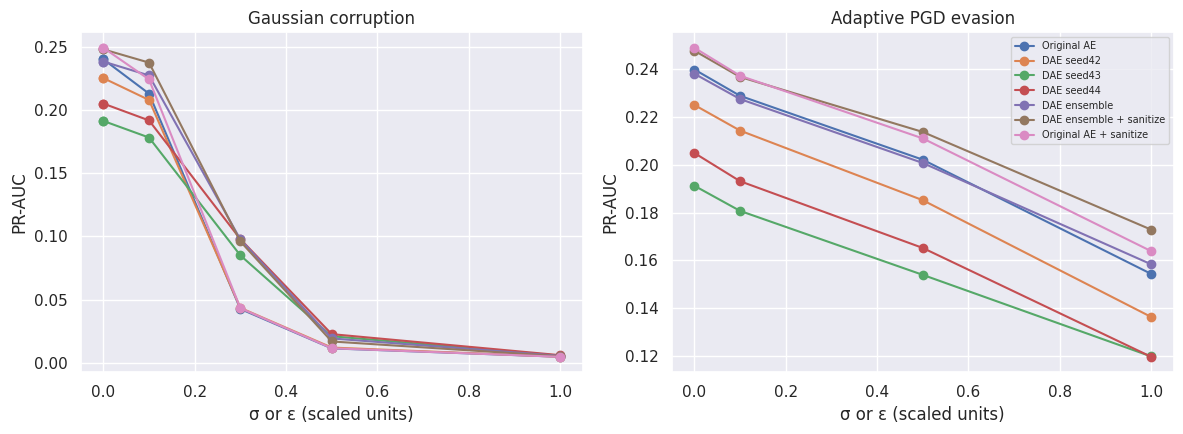

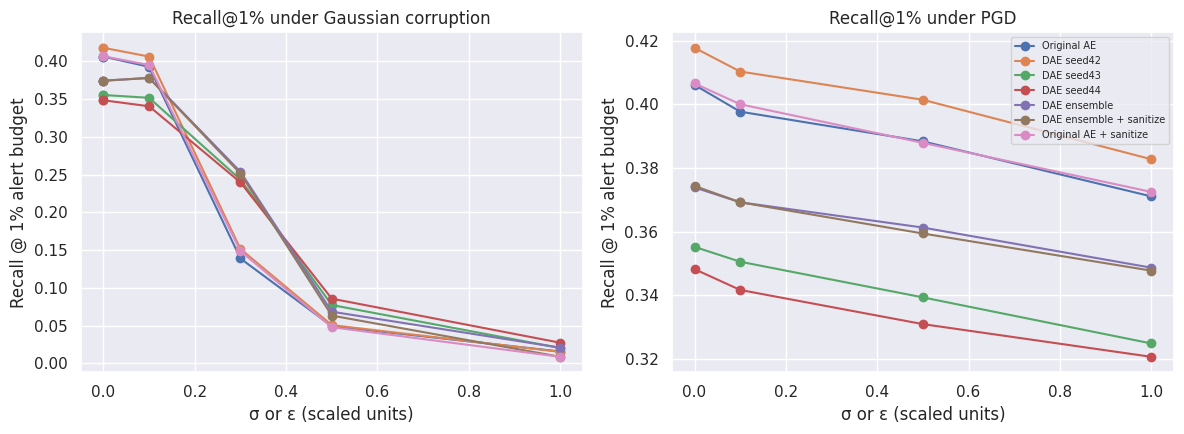

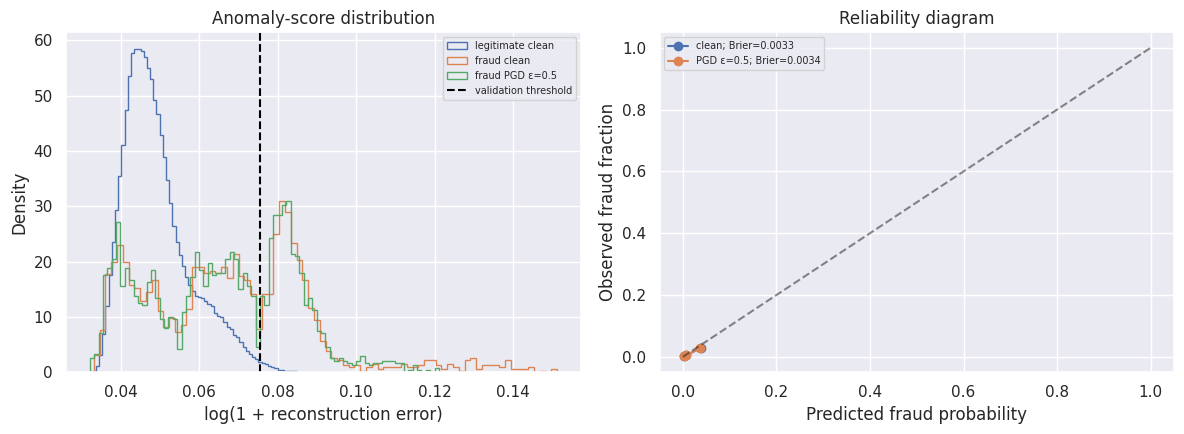

In [28]:
# ==========================================================
# Robustness curves
# ==========================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for name in PIPELINES:

    # Gaussian corruption
    d = section2[
        (section2.pipeline == name)
        &
        (section2.scenario == 'Gaussian noise')
    ].sort_values('strength')

    clean = section2[
        (section2.pipeline == name)
        &
        (section2.scenario == 'clean')
    ]

    axes[0].plot(
        [0] + d.strength.tolist(),
        [clean['PR-AUC'].iloc[0]] + d['PR-AUC'].tolist(),
        marker='o',
        label=name
    )

    # PGD
    d = section2[
        (section2.pipeline == name)
        &
        (section2.scenario == 'PGD')
    ].sort_values('strength')

    axes[1].plot(
        [0] + d.strength.tolist(),
        [clean['PR-AUC'].iloc[0]] + d['PR-AUC'].tolist(),
        marker='o',
        label=name
    )

axes[0].set_title('Gaussian corruption')
axes[1].set_title('Adaptive PGD evasion')

for ax in axes:
    ax.set_xlabel('σ or ε (scaled units)')
    ax.set_ylabel('PR-AUC')
    ax.grid(True)

axes[1].legend(fontsize=7)

fig.tight_layout()

fig.savefig(
    'outputs/figures/section2_robustness_curves.png',
    dpi=180
)

plt.show()


# ==========================================================
# Recall@1% robustness curves
# ==========================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for name in PIPELINES:

    clean = section2[
        (section2.pipeline == name)
        &
        (section2.scenario == 'clean')
    ]

    # Gaussian corruption
    d = section2[
        (section2.pipeline == name)
        &
        (section2.scenario == 'Gaussian noise')
    ].sort_values('strength')

    axes[0].plot(
        [0] + d.strength.tolist(),
        [clean['Recall_at_1pct_budget'].iloc[0]]
        + d['Recall_at_1pct_budget'].tolist(),
        marker='o',
        label=name
    )

    # PGD
    d = section2[
        (section2.pipeline == name)
        &
        (section2.scenario == 'PGD')
    ].sort_values('strength')

    axes[1].plot(
        [0] + d.strength.tolist(),
        [clean['Recall_at_1pct_budget'].iloc[0]]
        + d['Recall_at_1pct_budget'].tolist(),
        marker='o',
        label=name
    )

axes[0].set_title('Recall@1% under Gaussian corruption')
axes[1].set_title('Recall@1% under PGD')

for ax in axes:
    ax.set_xlabel('σ or ε (scaled units)')
    ax.set_ylabel('Recall @ 1% alert budget')
    ax.grid(True)

axes[1].legend(fontsize=7)

fig.tight_layout()

fig.savefig(
    'outputs/figures/section2_recall_robustness.png',
    dpi=180
)

plt.show()


# ==========================================================
# Confidence histogram + calibration diagram
# ==========================================================

name = 'DAE ensemble + sanitize'

clean_scores = pipeline_scores(
    name,
    X_te
)

attacked_scores = ATTACK_CACHE[name][1]

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 4.5)
)

# ----------------------------------------------------------
# Confidence histogram
# ----------------------------------------------------------

for label, values in [

    (
        'legitimate clean',
        clean_scores[y_te == 0]
    ),

    (
        'fraud clean',
        clean_scores[y_te == 1]
    ),

    (
        'fraud PGD ε=0.5',
        attacked_scores[y_te == 1]
    )

]:

    axes[0].hist(
        np.log1p(values),
        bins=80,
        density=True,
        histtype='step',
        label=label
    )

axes[0].axvline(
    np.log1p(THRESH2[name]),
    color='black',
    linestyle='--',
    label='validation threshold'
)

axes[0].set_title(
    'Anomaly-score distribution'
)

axes[0].set_xlabel(
    'log(1 + reconstruction error)'
)

axes[0].set_ylabel(
    'Density'
)

axes[0].legend(fontsize=7)


# ----------------------------------------------------------
# Reliability diagram
# ----------------------------------------------------------

val_s = pipeline_scores(
    name,
    X_va
)

cal = IsotonicRegression(
    out_of_bounds='clip'
).fit(
    val_s,
    y_va
)

for label, scores in [

    ('clean', clean_scores),

    ('PGD ε=0.5', attacked_scores)

]:

    probs = cal.predict(scores)

    frac, mean = calibration_curve(
        y_te,
        probs,
        n_bins=10,
        strategy='quantile'
    )

    axes[1].plot(
        mean,
        frac,
        marker='o',
        label=(
            f'{label}; '
            f'Brier='
            f'{brier_score_loss(y_te, probs):.4f}'
        )
    )

axes[1].plot(
    [0, 1],
    [0, 1],
    'k--',
    alpha=0.5
)

axes[1].set_title(
    'Reliability diagram'
)

axes[1].set_xlabel(
    'Predicted fraud probability'
)

axes[1].set_ylabel(
    'Observed fraud fraction'
)

axes[1].legend(fontsize=7)

fig.tight_layout()

fig.savefig(
    'outputs/figures/section2_scores_calibration.png',
    dpi=180
)

plt.show()

In [29]:
MUTABLE=[FI['log_amt'],FI['distance_km']]



def attack_fraud(name, X_fraud, epsilon, steps=1, batch_size=2048):
    models=PIPELINES[name]
    defended=name.endswith('+ sanitize')
    out=[]
    for start in range(0,len(X_fraud),batch_size):
        original=torch.as_tensor(X_fraud[start:start+batch_size],dtype=torch.float32,device=device)
        current=original.clone()
        step=epsilon if steps==1 else 2.0*epsilon/steps
        for _ in range(steps):
            current=current.detach().requires_grad_(True)
            # Differentiable clipping: adaptive attack can see the sanitization transform.
            xx=current.clone()
            if defended:
                lo=torch.as_tensor(LOW,device=device); hi=torch.as_tensor(HIGH,device=device)
                xx[:,CONT_IDX]=torch.maximum(torch.minimum(xx[:,CONT_IDX],hi),lo)
            obj=torch.stack([((m(xx)-xx)**2).mean(dim=1) for m in models]).mean(dim=0).sum()
            grad=torch.autograd.grad(obj,current)[0]
            with torch.no_grad():
                nxt=current.detach().clone()
                nxt[:,MUTABLE] -= step*grad[:,MUTABLE].sign()
                nxt[:,MUTABLE]=torch.max(torch.min(nxt[:,MUTABLE],original[:,MUTABLE]+epsilon),original[:,MUTABLE]-epsilon)
                # Distance is nonnegative in original units; standardized lower bound:
                dist_floor=float((0.0-scaler.mean_[SCALE_COLS.index('distance_km')])/scaler.scale_[SCALE_COLS.index('distance_km')])
                nxt[:,FI['distance_km']].clamp_(min=dist_floor)
                current=nxt
        out.append(current.detach().cpu().numpy())
    return np.concatenate(out,axis=0)



EPSILONS=[0.0,0.1,0.25,0.5]
SECTION2_ROWS=[]; ATTACK_CACHE={}



def evaluate(name,scenario,strength,X):
    s=pipeline_scores(name,X)
    thr=THRESH2[name]
    pred=s>=thr
    SECTION2_ROWS.append({'pipeline':name,'scenario':scenario,'strength':strength,
       'PR-AUC':average_precision_score(y_te,s),'ROC-AUC':roc_auc_score(y_te,s),
       'Precision_fixed':precision_score(y_te,pred,zero_division=0),
       'Recall_fixed':recall_score(y_te,pred,zero_division=0),
       'F1_fixed':f1_score(y_te,pred,zero_division=0),
       'Alert_rate_fixed':pred.mean(),
       'Recall_at_1pct_budget':recall_score(y_te,s>=np.quantile(s,0.99),zero_division=0)})
    return s



for name in PIPELINES:
    evaluate(name,'clean',0,X_te)
    for sigma in [0.05,0.1,0.15,0.2,0.3]:
        Xn=add_noise(X_te,sigma,np.random.default_rng(42))
        evaluate(name,'Gaussian noise',sigma,Xn)
    for method,steps in [('FGSM',1),('PGD',20)]:
        for eps in EPSILONS[1:]:
            attacked=attack_fraud(name,X_te[y_te==1],eps,steps=steps)
            Xa=X_te.copy(); Xa[y_te==1]=attacked
            s=evaluate(name,method,eps,Xa)
            if method=='PGD' and eps==0.5: ATTACK_CACHE[name]=(Xa,s)
section2=pd.DataFrame(SECTION2_ROWS)
for pipe in section2.pipeline.unique():



    clean_prauc = section2[
        (section2.pipeline==pipe)
        &
        (section2.scenario=='clean')
    ]['PR-AUC'].iloc[0]



    section2.loc[
        section2.pipeline==pipe,
        'PR_AUC_retention'
    ] = (
        section2.loc[
            section2.pipeline==pipe,
            'PR-AUC'
        ] / clean_prauc
    )
section2.to_csv('outputs/results/section2_metrics.csv',index=False)
display(section2.round(4))

,pipeline,scenario,strength,PR-AUC,ROC-AUC,Precision_fixed,Recall_fixed,F1_fixed,Alert_rate_fixed,Recall_at_1pct_budget,PR_AUC_retention
0,Original AE,clean,0.00,0.2400,0.6813,0.1747,0.3916,0.2416,0.0087,0.4061,1.0000
1,Original AE,Gaussian noise,0.05,0.2348,0.6816,0.1632,0.4005,0.2318,0.0095,0.4065,0.9785
2,Original AE,Gaussian noise,0.10,0.2128,0.6820,0.1296,0.4117,0.1972,0.0123,0.3925,0.8869
3,Original AE,Gaussian noise,0.15,0.1652,0.6822,0.0869,0.4280,0.1444,0.0190,0.3585,0.6885
4,Original AE,Gaussian noise,0.20,0.1079,0.6820,0.0518,0.4438,0.0928,0.0331,0.2951,0.4497
...,...,...,...,...,...,...,...,...,...,...,...
79,Original AE + sanitize,FGSM,0.25,0.2428,0.6775,0.1769,0.3977,0.2449,0.0087,0.4103,0.9745
80,Original AE + sanitize,FGSM,0.50,0.3006,0.7095,0.1921,0.4401,0.2675,0.0088,0.4466,1.2068
81,Original AE + sanitize,PGD,0.10,0.2374,0.6752,0.1728,0.3865,0.2388,0.0086,0.4000,0.9529
82,Original AE + sanitize,PGD,0.25,0.2272,0.6720,0.1712,0.3823,0.2365,0.0086,0.3939,0.9120


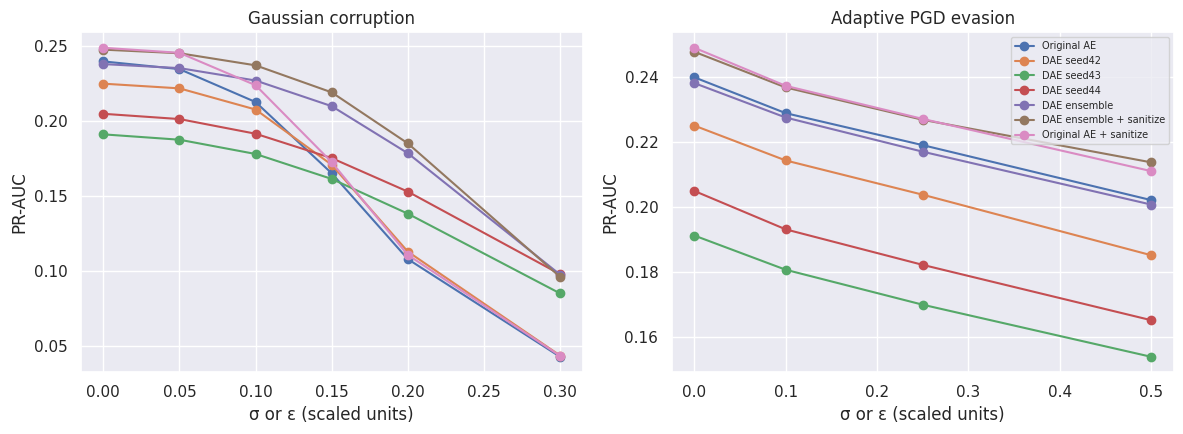

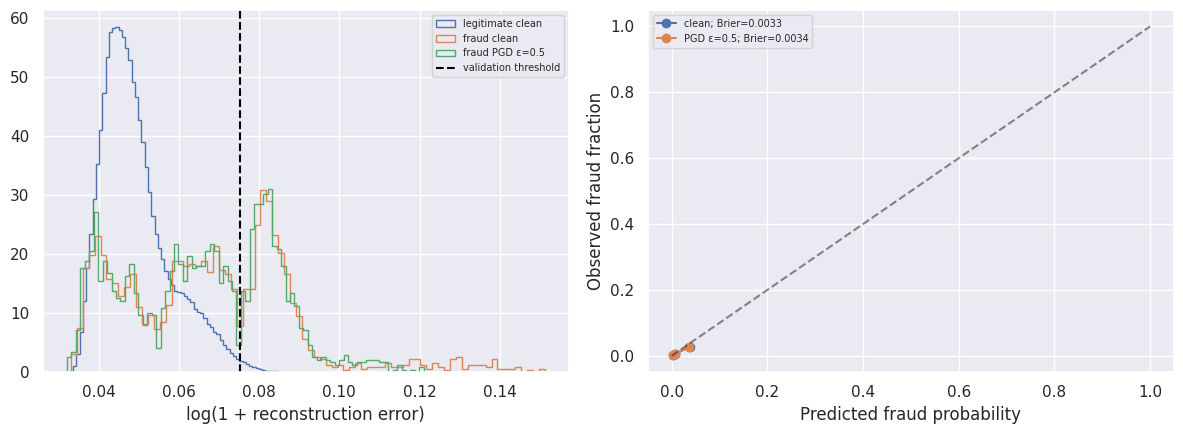

In [30]:
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for name in PIPELINES:
    for ax,scenario in zip(axes,['Gaussian noise','PGD']):
        d=section2[(section2.pipeline==name)&(section2.scenario==scenario)].sort_values('strength')
        clean=section2[(section2.pipeline==name)&(section2.scenario=='clean')]
        ax.plot([0]+d.strength.tolist(),[clean['PR-AUC'].iloc[0]]+d['PR-AUC'].tolist(),marker='o',label=name)
for ax,title in zip(axes,['Gaussian corruption','Adaptive PGD evasion']):
    ax.set_title(title);ax.set_xlabel('σ or ε (scaled units)');ax.set_ylabel('PR-AUC');ax.grid(True)
axes[1].legend(fontsize=7);fig.tight_layout();fig.savefig('outputs/figures/section2_robustness_curves.png',dpi=180)
plt.show()



name='DAE ensemble + sanitize'
clean_scores=pipeline_scores(name,X_te)
attacked_scores=ATTACK_CACHE[name][1]
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for label,v in [('legitimate clean',clean_scores[y_te==0]),('fraud clean',clean_scores[y_te==1]),('fraud PGD ε=0.5',attacked_scores[y_te==1])]:
    axes[0].hist(np.log1p(v),bins=80,density=True,histtype='step',label=label)
axes[0].axvline(np.log1p(THRESH2[name]),color='black',linestyle='--',label='validation threshold')
axes[0].set_xlabel('log(1 + reconstruction error)');axes[0].legend(fontsize=7)



# Calibration is diagnostic only, using labels from validation; no labels used in AE training.
val_s=pipeline_scores(name,X_va)
cal=IsotonicRegression(out_of_bounds='clip').fit(val_s,y_va)
for label,s in [('clean',clean_scores),('PGD ε=0.5',attacked_scores)]:
    probs=cal.predict(s)
    frac,mean=calibration_curve(y_te,probs,n_bins=10,strategy='quantile')
    axes[1].plot(mean,frac,marker='o',label=f'{label}; Brier={brier_score_loss(y_te,probs):.4f}')
axes[1].plot([0,1],[0,1],'k--',alpha=0.5);axes[1].set_xlabel('Predicted fraud probability')
axes[1].set_ylabel('Observed fraud fraction');axes[1].legend(fontsize=7)
fig.tight_layout();fig.savefig('outputs/figures/section2_scores_calibration.png',dpi=180);plt.show()

In [29]:
# 2.4 Latency and throughput: scoring only, excludes adversarial generation time.
# 1-thread CPU when possible; same input set and same warm-up for all pipelines.
import os
try: torch.set_num_threads(1)
except RuntimeError: pass
EFF=[]
for name in PIPELINES:
    for scenario,X in [('clean',X_te),('Gaussian σ=0.25',add_noise(X_te,0.25,np.random.default_rng(42))),
                       ('PGD ε=0.5',ATTACK_CACHE[name][0])]:
        sample=X[:1]
        for _ in range(20):pipeline_scores(name,sample)
        times=[]
        for _ in range(200):
            t=time.perf_counter();pipeline_scores(name,sample);times.append((time.perf_counter()-t)*1000)
        t=time.perf_counter();pipeline_scores(name,X); elapsed=time.perf_counter()-t
        EFF.append({'pipeline':name,'scenario':scenario,'p50_ms':np.percentile(times,50),
                    'p90_ms':np.percentile(times,90),'throughput_tps':len(X)/elapsed,
                    'parameters_total':sum(sum(p.numel() for p in m.parameters()) for m in PIPELINES[name]),
                    'model_weight_bytes':sum(sum(p.numel()*p.element_size() for p in m.parameters()) for m in PIPELINES[name])})
eff2=pd.DataFrame(EFF);eff2.to_csv('outputs/results/section2_efficiency.csv',index=False)
display(eff2.round(3))

# Curated cases: clean baseline errors, PGD evasion, and cases corrected by the defended pipeline.
base_clean=pipeline_scores('Original AE',X_te)
base_attack_X,base_attack_s=ATTACK_CACHE['Original AE']
robust_attack_s=pipeline_scores('DAE ensemble + sanitize',base_attack_X)
base_wrong=(base_attack_s>=THRESH2['Original AE'])!=(y_te==1)
robust_right=(robust_attack_s>=THRESH2['DAE ensemble + sanitize'])==(y_te==1)
resolved=np.where(base_wrong & robust_right)[0]
unresolved=np.where(base_wrong & ~robust_right)[0]
chosen=np.r_[resolved[:3],unresolved[:7]][:10]
if len(chosen)<6:
    extra=np.where(base_wrong)[0];chosen=np.unique(np.r_[chosen,extra[:10]])[:10]
case_rows=[]
for idx in chosen:
    expected=int(y_te[idx]); old_pred=int(base_attack_s[idx]>=THRESH2['Original AE'])
    new_pred=int(robust_attack_s[idx]>=THRESH2['DAE ensemble + sanitize'])
    case_rows.append({'test_index':int(idx),'expected_fraud':expected,'baseline_prediction':old_pred,
       'adapted_prediction':new_pred,'baseline_score':float(base_attack_s[idx]),
       'baseline_threshold':THRESH2['Original AE'],'adapted_score':float(robust_attack_s[idx]),
       'adapted_threshold':THRESH2['DAE ensemble + sanitize'],
       'baseline_calibrated_probability':float(cal.predict([base_attack_s[idx]])[0]),
       'adapted_calibrated_probability':float(cal.predict([robust_attack_s[idx]])[0]),
       'resolved':bool(old_pred!=expected and new_pred==expected),
       'commentary_to_complete':'Inspect feature values, attack perturbations, and raw record; do not infer cause from score alone.'})
cases=pd.DataFrame(case_rows);cases.to_csv('outputs/results/section2_failure_cases.csv',index=False)
display(cases)
print('Resolved cases:',int(cases.resolved.sum()),'; rubric requests >=2. If fewer, report honestly and adjust defense.')


,pipeline,scenario,p50_ms,p90_ms,throughput_tps,parameters_total,model_weight_bytes
0,Original AE,clean,0.561,0.692,2.101702e+07,1154,4616
1,Original AE,Gaussian σ=0.25,0.564,2.663,2.087708e+07,1154,4616
2,Original AE,PGD ε=0.5,0.542,0.598,2.079452e+07,1154,4616
3,DAE seed42,clean,0.549,0.645,2.128960e+07,1154,4616
4,DAE seed42,Gaussian σ=0.25,0.529,0.584,2.137261e+07,1154,4616
5,DAE seed42,PGD ε=0.5,0.519,0.569,2.166078e+07,1154,4616
6,DAE seed43,clean,0.582,0.708,2.095335e+07,1154,4616
7,DAE seed43,Gaussian σ=0.25,0.559,0.663,2.112443e+07,1154,4616
8,DAE seed43,PGD ε=0.5,0.597,0.734,1.891789e+07,1154,4616
9,DAE seed44,clean,0.692,0.731,1.914206e+07,1154,4616


,test_index,expected_fraud,baseline_prediction,adapted_prediction,baseline_score,baseline_threshold,adapted_score,adapted_threshold,baseline_calibrated_probability,adapted_calibrated_probability,resolved,commentary_to_complete
0,951,0,1,0,0.071159,0.066317,0.070105,0.078249,0.012586,0.012360,True,"Inspect feature values, attack perturbations, ..."
1,1428,0,1,0,0.067075,0.066317,0.064341,0.078249,0.010682,0.007093,True,"Inspect feature values, attack perturbations, ..."
2,1857,1,0,1,0.063703,0.066317,0.081025,0.078249,0.007093,0.045181,True,"Inspect feature values, attack perturbations, ..."
3,1685,1,0,0,0.045267,0.066317,0.064345,0.078249,0.002126,0.007093,False,"Inspect feature values, attack perturbations, ..."
4,1695,0,1,1,0.071250,0.066317,0.083508,0.078249,0.012586,0.254717,False,"Inspect feature values, attack perturbations, ..."
5,1781,1,0,0,0.060557,0.066317,0.070174,0.078249,0.006294,0.012360,False,"Inspect feature values, attack perturbations, ..."
6,1891,1,0,0,0.047465,0.066317,0.069305,0.078249,0.002126,0.012360,False,"Inspect feature values, attack perturbations, ..."
7,2039,1,0,0,0.062850,0.066317,0.068739,0.078249,0.007093,0.011292,False,"Inspect feature values, attack perturbations, ..."
8,2173,1,0,0,0.045761,0.066317,0.056102,0.078249,0.002126,0.002126,False,"Inspect feature values, attack perturbations, ..."
9,2195,1,0,0,0.030805,0.066317,0.038422,0.078249,0.000000,0.002126,False,"Inspect feature values, attack perturbations, ..."


Resolved cases: 3 ; rubric requests >=2. If fewer, report honestly and adjust defense.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [30]:
import os

try:
    torch.set_num_threads(1)
except RuntimeError:
    pass

EFF = []

for name in PIPELINES:

    scenarios = [

        (
            'clean',
            X_te
        ),

        (
            'Gaussian σ=0.25',
            add_noise(
                X_te,
                0.25,
                np.random.default_rng(42)
            )
        ),

        (
            'PGD ε=0.5',
            ATTACK_CACHE[name][0]
        )

    ]

    model_params = sum(
        sum(p.numel() for p in m.parameters())
        for m in PIPELINES[name]
    )

    model_bytes = sum(
        sum(
            p.numel() * p.element_size()
            for p in m.parameters()
        )
        for m in PIPELINES[name]
    )

    for scenario, X in scenarios:

        sample = X[:1]

        # warm-up
        for _ in range(20):
            pipeline_scores(name, sample)

        times = []

        for _ in range(200):

            t0 = time.perf_counter()

            pipeline_scores(name, sample)

            times.append(
                (time.perf_counter() - t0) * 1000
            )

        t0 = time.perf_counter()

        pipeline_scores(name, X)

        elapsed = time.perf_counter() - t0

        EFF.append({

            'pipeline': name,
            'scenario': scenario,

            'p50_ms':
                np.percentile(times, 50),

            'p90_ms':
                np.percentile(times, 90),

            'p95_ms':
                np.percentile(times, 95),

            'throughput_tps':
                len(X) / elapsed,

            'parameters_total':
                model_params,

            'model_size_kb':
                model_bytes / 1024

        })

eff2 = pd.DataFrame(EFF)

eff2.to_csv(
    'outputs/results/section2_efficiency.csv',
    index=False
)

display(
    eff2.round(3)
)

# ==========================================================
# Failure case analysis
# ==========================================================

base_clean = pipeline_scores(
    'Original AE',
    X_te
)

base_attack_X, base_attack_s = ATTACK_CACHE[
    'Original AE'
]

robust_attack_s = pipeline_scores(
    'DAE ensemble + sanitize',
    base_attack_X
)

base_wrong = (
    (base_attack_s >= THRESH2['Original AE'])
    !=
    (y_te == 1)
)

robust_right = (
    (robust_attack_s >= THRESH2['DAE ensemble + sanitize'])
    ==
    (y_te == 1)
)

resolved = np.where(
    base_wrong & robust_right
)[0]

unresolved = np.where(
    base_wrong & ~robust_right
)[0]

chosen = np.r_[
    resolved[:3],
    unresolved[:7]
][:10]

if len(chosen) < 6:

    extra = np.where(base_wrong)[0]

    chosen = np.unique(
        np.r_[
            chosen,
            extra[:10]
        ]
    )[:10]

feature_cols = []

for feat in [

    'log_amt',
    'distance_km',
    'txn_count_1h',
    'txn_count_24h'

]:

    if feat in FI:
        feature_cols.append(feat)

case_rows = []

for idx in chosen:

    expected = int(y_te[idx])

    old_pred = int(
        base_attack_s[idx]
        >=
        THRESH2['Original AE']
    )

    new_pred = int(
        robust_attack_s[idx]
        >=
        THRESH2['DAE ensemble + sanitize']
    )

    row = {

        'test_index':
            int(idx),

        'expected_fraud':
            expected,

        'baseline_prediction':
            old_pred,

        'adapted_prediction':
            new_pred,

        'baseline_score':
            float(base_attack_s[idx]),

        'adapted_score':
            float(robust_attack_s[idx]),

        'baseline_threshold':
            THRESH2['Original AE'],

        'adapted_threshold':
            THRESH2[
                'DAE ensemble + sanitize'
            ],

        'baseline_probability':
            float(
                cal.predict(
                    [base_attack_s[idx]]
                )[0]
            ),

        'adapted_probability':
            float(
                cal.predict(
                    [robust_attack_s[idx]]
                )[0]
            ),

        'resolved':
            bool(
                old_pred != expected
                and
                new_pred == expected
            )

    }

    for feat in feature_cols:

        row[feat] = float(
            X_te[idx, FI[feat]]
        )

    case_rows.append(row)

cases = pd.DataFrame(case_rows)

cases.to_csv(
    'outputs/results/section2_failure_cases.csv',
    index=False
)

display(cases)

print(
    'Resolved cases:',
    int(cases.resolved.sum())
)

if int(cases.resolved.sum()) < 2:

    print(
        'Warning: fewer than 2 resolved cases.'
    )



,pipeline,scenario,p50_ms,p90_ms,p95_ms,throughput_tps,parameters_total,model_size_kb
0,Original AE,clean,0.436,0.508,0.517,2.190061e+07,1154,4.508
1,Original AE,Gaussian σ=0.25,0.435,0.496,0.516,2.234944e+07,1154,4.508
2,Original AE,PGD ε=0.5,0.451,0.627,0.668,2.187174e+07,1154,4.508
3,DAE seed42,clean,0.432,0.475,0.509,2.179804e+07,1154,4.508
4,DAE seed42,Gaussian σ=0.25,0.465,0.743,0.791,2.225824e+07,1154,4.508
5,DAE seed42,PGD ε=0.5,0.428,0.482,0.502,2.182809e+07,1154,4.508
6,DAE seed43,clean,0.434,0.499,0.530,2.191747e+07,1154,4.508
7,DAE seed43,Gaussian σ=0.25,0.436,0.491,0.519,2.189427e+07,1154,4.508
8,DAE seed43,PGD ε=0.5,0.437,0.519,0.555,2.240595e+07,1154,4.508
9,DAE seed44,clean,0.447,0.726,0.764,2.168666e+07,1154,4.508


,test_index,expected_fraud,baseline_prediction,adapted_prediction,baseline_score,adapted_score,baseline_threshold,adapted_threshold,baseline_probability,adapted_probability,resolved,log_amt,distance_km
0,951,0,1,0,0.071159,0.070105,0.066317,0.078249,0.012586,0.012360,True,3.521833,1.344262
1,1428,0,1,0,0.067075,0.064341,0.066317,0.078249,0.010682,0.007093,True,3.254941,0.965998
2,1857,1,0,1,0.063703,0.081025,0.066317,0.078249,0.007093,0.045181,True,2.486248,-0.535655
3,1685,1,0,0,0.045267,0.064345,0.066317,0.078249,0.002126,0.007093,False,-0.217694,0.156257
4,1695,0,1,1,0.071250,0.083508,0.066317,0.078249,0.012586,0.254717,False,2.528798,1.550312
5,1781,1,0,0,0.060557,0.070174,0.066317,0.078249,0.006294,0.012360,False,2.248981,-1.623366
6,1891,1,0,0,0.047465,0.069305,0.066317,0.078249,0.002126,0.012360,False,-0.289677,0.622182
7,2039,1,0,0,0.062850,0.068739,0.066317,0.078249,0.007093,0.011292,False,2.344566,-0.208405
8,2173,1,0,0,0.045761,0.056102,0.066317,0.078249,0.002126,0.002126,False,-1.002916,-0.408571
9,2195,1,0,0,0.030805,0.038422,0.066317,0.078249,0.000000,0.002126,False,1.753285,0.072367


Resolved cases: 3
